In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re
from pathlib import Path

In [2]:
RAW_DATA_DIR = Path("raw")

OUTPUT_FILE = "raw/raw_data_metadata.csv"

column_meanings = {
    "Sno.": "Unique serial number assigned to a candidate.",
    "Candidate": "Name of the candidate contesting the election.",
    "Party": "Political party represented by the candidate.",
    "Criminal Cases": "Number of criminal cases declared by the candidate.",
    "Education": "Educational qualification declared by the candidate.",
    "Age": "Age of the candidate.",
    "Total Assets": "Total declared assets owned by the candidate.",
    "Liabilities": "Total declared liabilities or debts of the candidate.",
    "State": "Name of the state in which the candidate participated.",
    "Constituency": "Name of the electoral constituency.",
    "Election Year": "Year in which the election was conducted.",
    "Constituency No.": "Unique Serial number assigned to constituency.",
    "Winner Candidate": "Name of the candidate who won the election in the respective constituency in that election year.",
    "Winner Party": "Political party name as recorded in the Myneta dataset for the winning candidate.",
    "Winner Party Source": "Political party of the winning candidate."
}

metadata = []

for file_path in RAW_DATA_DIR.glob("*"):
    df = pd.read_csv(file_path)

    rows, columns = df.shape
    for column in df.columns:
        metadata.append({
            "File Name": file_path.name,
            "Number of Rows": rows,
            "Number of Columns": columns,
            "Column Name": column,
            "Data Type": str(df[column].dtype),
            "Meaning": column_meanings.get(
                column,
                "Meaning not documented yet."
            )
        })

metadata_df = pd.DataFrame(metadata)

# metadata_df.to_csv(OUTPUT_FILE, index=False)

print(f"Metadata saved to {OUTPUT_FILE}")
print(f"Total datasets processed: {metadata_df['File Name'].nunique()}")
print(f"Total column entries: {len(metadata_df)}")

Metadata saved to raw/raw_data_metadata.csv
Total datasets processed: 11
Total column entries: 85


## **1. Cleaning columns** 
Helper functions to clean candidate names and convert age, total assets, liabilities into numeric form in data

In [3]:
def clean_candidate(name):
    if not isinstance(name, str):
        return name

    prefixes = r'^(?:(?:Adv|Dr|Mr|Mrs|Ms|Shri|Smt|Prof)\.?\s+)+'
    name = re.sub(prefixes, "", name, flags=re.IGNORECASE)

    lineage_field = r'\s+(?:S/o|D/o|W/o|C/o|H/o|@)\.?\s+.*$'
    name = re.sub(lineage_field, "", name, flags=re.IGNORECASE)

    name = name.split(",", 1)[0]
    name = name.split("(", 1)[0]
    name = name.replace(".", " ")

    words = name.split()
    words = [word.capitalize() for word in words]
    return " ".join(words)

In [4]:
def clean_age(age):
    age = pd.to_numeric(age, errors="coerce")
    return int(age) if pd.notna(age) else -1

In [5]:
def clean_money(money):
    amount = re.search(r'(?<=Rs[.\s])([\d,]+)', money)
    if amount:
        amount = amount.group(1)
    else:
        return -1

    return int(amount.replace(",",""))

In [6]:
datasets = [(s, y) for s in ("andhra", "bihar", "gujarat") for y in (2014, 2019, 2024)]

def build_row_log(state, year):
    key = f"{state}_{year}"
    raw = pd.read_csv(f"interim/ocr_data/{key}.csv")      # RAW file, not cleaned_frames
    log = pd.DataFrame({"file": key, "Sno.": raw["Sno."]})

    # Candidate: was the name text changed?
    cleaned_name = raw["Candidate"].apply(clean_candidate)
    log["name_changed"] = raw["Candidate"].astype(str).ne(cleaned_name.astype(str))

    # Age: invalid (became -1) vs. content changed vs. only type-converted
    age_clean = raw["Age"].apply(clean_age)
    age_num   = pd.to_numeric(raw["Age"], errors="coerce")
    log["age_invalid"]      = age_clean.eq(-1)
    log["age_invalid_why"]  = None
    log.loc[raw["Age"].isna(), "age_invalid_why"] = "missing (NaN)"
    log.loc[age_num.isna() & raw["Age"].notna(), "age_invalid_why"] = "non-numeric text"
    log["age_value_changed"] = age_num.isna() | age_num.ne(age_clean)   # e.g. 49.5 -> 49, or -> -1

    # Money columns: invalid (-1) vs. reformatted ("Rs 1,76,20,000 ~ 1 Crore+" -> 17620000)
    for col, short in [("Total Assets", "assets"), ("Liabilities", "liab")]:
        cleaned = raw[col].apply(clean_money)
        log[f"{short}_invalid"]     = cleaned.eq(-1)
        log[f"{short}_reformatted"] = cleaned.ne(-1)   # parsed text -> int, so the value changed

    log["any_invalid"] = log[["age_invalid", "assets_invalid", "liab_invalid"]].any(axis=1)
    return log

row_log = pd.concat([build_row_log(s, y) for s, y in datasets], ignore_index=True)

flag_cols = [c for c in row_log.columns if row_log[c].dtype == bool]
summary = row_log.groupby("file")[flag_cols].sum()
summary.loc["TOTAL"] = summary.sum()
summary.insert(0, "total_rows", list(row_log.groupby("file").size()) + [len(row_log)])
print(summary.T)

file                andhra_2014  andhra_2019  andhra_2024  bihar_2014  \
total_rows                  329          314          450         605   
name_changed                 30           49           85          28   
age_invalid                   7            3            0           6   
age_value_changed             7            3            0           6   
assets_invalid                8            5           11           2   
assets_reformatted          321          309          439         603   
liab_invalid                  0            0            0           0   
liab_reformatted            329          314          450         605   
any_invalid                  14            8           11           8   

file                bihar_2019  bihar_2024  gujarat_2014  gujarat_2019  \
total_rows                 619         496           333           371   
name_changed                30          19            13            16   
age_invalid                  0           0     

In [7]:
andhra_14 = pd.read_csv("interim/ocr_data/andhra_2014.csv")
andhra_14.head()

,Sno.,Candidate,Party,Criminal Cases,Education,Age,Total Assets,Liabilities
0,1,Abburi Koteswara Rao,Pyramid Party of India,0,10th Pass,49,"Rs 1,76,20,000\r\n~ 1 Crore+","Rs 38,00,000\r\n~ 38 Lacs+"
1,2,Abdul Waheed Shaik,INC,0,10th Pass,44,"Rs 76,54,500\r\n~ 76 Lacs+","Rs 70,00,000\r\n~ 70 Lacs+"
2,3,Adala Prabhakara Reddy,TDP,0,12th Pass,64,"Rs 1,28,25,85,640\r\n~ 128 Crore+","Rs 13,16,46,350\r\n~ 13 Crore+"
3,4,Aithabathula Jogeswara Venkata Butchi Maheswar...,INC,1,Post Graduate,63,"Rs 1,26,25,844\r\n~ 1 Crore+","Rs 25,04,500\r\n~ 25 Lacs+"
4,5,Akki Reddy Bhimanadula,Pyramid Party of India,0,10th Pass,33,"Rs 6,44,500\r\n~ 6 Lacs+",Rs 0\r\n~


**Dtypes check before Cleaning**

In [8]:
andhra_14.dtypes

Sno.              int64
Candidate           str
Party               str
Criminal Cases    int64
Education           str
Age                 str
Total Assets        str
Liabilities         str
dtype: object

In [9]:
andhra_14["Candidate"] = andhra_14["Candidate"].apply(clean_candidate)
andhra_14["Age"] = andhra_14["Age"].apply(clean_age)
andhra_14["Total Assets"] = andhra_14["Total Assets"].apply(clean_money)
andhra_14["Liabilities"] = andhra_14["Liabilities"].apply(clean_money)

**Dtypes after Cleaning**

In [10]:
andhra_14.dtypes

Sno.              int64
Candidate           str
Party               str
Criminal Cases    int64
Education           str
Age               int64
Total Assets      int64
Liabilities       int64
dtype: object

In [11]:
datasets = [
    ("andhra", 2014),
    ("andhra", 2019),
    ("andhra", 2024),
    ("bihar", 2014),
    ("bihar", 2019),
    ("bihar", 2024),
    ("gujarat", 2014),
    ("gujarat", 2019),
    ("gujarat", 2024),
]

numeric_column = {"Age", "Total Assets", "Liabilities"}

def is_missing_value(series, column_name):
    missing = series.isna()
    if column_name in numeric_column:
        numeric_values = pd.to_numeric(series, errors="coerce")
        missing = missing | numeric_values.eq(-1)
    else:
        missing = missing | series.astype(str).str.strip().eq("")
    return missing

cleaned_frames = {}

for state, year in datasets:
    file_key = f"{state}_{year}"
    df = pd.read_csv(f"interim/ocr_data/{file_key}.csv")

    df["Candidate"] = df["Candidate"].apply(clean_candidate)
    df["Age"] = df["Age"].apply(clean_age)
    df["Total Assets"] = df["Total Assets"].apply(clean_money)
    df["Liabilities"] = df["Liabilities"].apply(clean_money)
    cleaned_frames[file_key] = df

print(f"Loaded and cleaned {len(cleaned_frames)} datasets in memory.")
print(f"Cleaned files will be saved directly to: interim/cleaned_data/")

Loaded and cleaned 9 datasets in memory.
Cleaned files will be saved directly to: interim/cleaned_data/


In [12]:
for file_key, frame in cleaned_frames.items():
    print(f'\n{file_key}')
    print(f'Rows: {len(frame)}')
    print(f'Columns: {frame.columns.tolist()}')


andhra_2014
Rows: 329
Columns: ['Sno.', 'Candidate', 'Party', 'Criminal Cases', 'Education', 'Age', 'Total Assets', 'Liabilities']

andhra_2019
Rows: 314
Columns: ['Sno.', 'Candidate', 'Party', 'Criminal Cases', 'Education', 'Age', 'Total Assets', 'Liabilities']

andhra_2024
Rows: 450
Columns: ['Sno.', 'Candidate', 'Party', 'Criminal Cases', 'Education', 'Age', 'Total Assets', 'Liabilities']

bihar_2014
Rows: 605
Columns: ['Sno.', 'Candidate', 'Party', 'Criminal Cases', 'Education', 'Age', 'Total Assets', 'Liabilities']

bihar_2019
Rows: 619
Columns: ['Sno.', 'Candidate', 'Party', 'Criminal Cases', 'Education', 'Age', 'Total Assets', 'Liabilities']

bihar_2024
Rows: 496
Columns: ['Sno.', 'Candidate', 'Party', 'Criminal Cases', 'Education', 'Age', 'Total Assets', 'Liabilities']

gujarat_2014
Rows: 333
Columns: ['Sno.', 'Candidate', 'Party', 'Criminal Cases', 'Education', 'Age', 'Total Assets', 'Liabilities']

gujarat_2019
Rows: 371
Columns: ['Sno.', 'Candidate', 'Party', 'Criminal Case

In [13]:
# for file in cleaned_frames:
#     df = cleaned_frames[file]
#     df.to_csv(f"interim/cleaned_raw_data/{file}.csv", index=False)

## **2. Removing Duplicates in Data**

In [14]:
import itertools
from rapidfuzz.distance import JaroWinkler
def std_name(s):
    s = s.lower()
    s = re.sub(r"\.", " ", s)
    splitted = s.split()
    cleaned_words = [i for i in splitted]
    return " ".join(cleaned_words)


def names_agree(a, b):
    words_a = a.split()
    words_b = b.split()
    if len(words_a) <= len(words_b):
        short, long = words_a, words_b
    else:
        short, long = words_b, words_a

    def words_match(w1, w2):
        if len(w1) == 1 or len(w2) == 1:
            return w1[0] == w2[0]
        return JaroWinkler.similarity(w1, w2) >= 0.85

    for perm in itertools.permutations(long, len(short)):
        if all(words_match(s, l) for s, l in zip(short, perm)):
            return True
    return False


def find_dups(df: pd.DataFrame):
    sorted_df = df.sort_values(by="Age")
    sorted_df['Candidate'] = sorted_df['Candidate'].apply(std_name)
    sorted_df['Party'] = sorted_df['Party'].apply(std_name)
    sorted_df['Education'] = sorted_df['Education'].apply(std_name)
    n = len(sorted_df)

    dup_pairs = []

    for i in range(n):
        row_i = sorted_df.iloc[i]
        id_i = row_i['Sno.']
        for j in range(i+1,n):
            row_j = sorted_df.iloc[j]
            if abs(row_j['Age']-row_i['Age']) > 1:
                break
            if row_j['Criminal Cases']!=row_i['Criminal Cases']:
                continue
            if row_j['Party']!=row_i['Party']:
                continue
            if not names_agree(row_i['Candidate'],row_j['Candidate']):
                continue
            id_j = row_j['Sno.']
            dup_pairs.append((int(id_i)-1,int(id_j)-1))

    return dup_pairs

In [15]:
dups = find_dups(cleaned_frames['andhra_2014'])
print(dups)

[(65, 66)]


In [16]:
cleaned_frames["andhra_2014"].drop(65, inplace=True)

In [17]:
dups = find_dups(cleaned_frames['andhra_2019'])
print(dups)

[(249, 257), (79, 243), (87, 88)]


In [18]:
cleaned_frames["andhra_2019"].drop(87, inplace=True)

In [19]:
dups = find_dups(cleaned_frames['andhra_2024'])
print(dups)

[(150, 39), (431, 430), (315, 418)]


In [20]:
cleaned_frames["andhra_2024"].drop(430, inplace=True)

In [21]:
dups = find_dups(cleaned_frames['bihar_2014'])
print(dups)

[(593, 589), (441, 388)]


In [22]:
dups_ = find_dups(cleaned_frames['bihar_2019'])
print(dups_)

[(360, 374), (284, 225), (590, 591), (587, 588)]


In [23]:
cleaned_frames['bihar_2019'].drop(index=[591,588], inplace=True)

In [24]:
dups__ = find_dups(cleaned_frames['bihar_2024'])
print(dups__)

[(361, 362), (3, 38), (475, 476), (470, 471), (51, 52)]


In [25]:
cleaned_frames['bihar_2024'].iloc[361]

Sno.                       362
Candidate         Ranjan Kumar
Party                      IND
Criminal Cases               0
Education             Graduate
Age                         28
Total Assets           6107000
Liabilities                  0
Name: 361, dtype: object

In [26]:
cleaned_frames['bihar_2024'].iloc[362]

Sno.                       363
Candidate         Ranjan Kumar
Party                      IND
Criminal Cases               0
Education            12th Pass
Age                         29
Total Assets           1632000
Liabilities                  0
Name: 362, dtype: object

In [27]:
cleaned_frames['bihar_2024'].drop(index=[475,470], inplace=True)

In [28]:
dup_guj = find_dups(cleaned_frames['gujarat_2014'])
print(dup_guj)

[(247, 246)]


In [29]:
cleaned_frames['gujarat_2014'].drop(246, inplace=True)

In [30]:
dup_guj_ = find_dups(cleaned_frames['gujarat_2019'])
print(dup_guj_)

[(294, 256), (256, 254), (36, 35), (86, 85), (173, 7)]


In [31]:
cleaned_frames['gujarat_2019'].iloc[254:257]

,Sno.,Candidate,Party,Criminal Cases,Education,Age,Total Assets,Liabilities
254,255,Rajeshbhai Solanki,IND,0,12th Pass,37,246000,0
255,256,Raju Parmar,INC,0,Graduate,68,262997727,18943977
256,257,Rakeshbhai,IND,0,10th Pass,37,801500,0


In [32]:
cleaned_frames['gujarat_2019'].drop(index=[35,85], inplace=True)

In [33]:
dup_guj__ = find_dups(cleaned_frames['gujarat_2024'])
print(dup_guj__)

[(174, 173)]


In [34]:
cleaned_frames['gujarat_2024'].drop(173, inplace=True)

# **3. Missingness Tests**

# Missingness mechanism tests per state/year file

This notebook reads the nine cleaned csv files in **cleaned_data/cleaned_raw_data** (three states x three election years). For **Age, Total Assets, and Liabilities**, the value **-1** is treated as missing.

The missingness test is run **separately on each of the nine state/year files** (Andhra Pradesh, Bihar, Gujarat x 2014, 2019, 2024). For each file and each target column with missing values, a **Chi-square test of independence** checks whether being missing is associated with each observed candidate characteristic.

In [35]:
from pathlib import Path
import math
import pandas as pd
import numpy as np

SENTINEL_NUMERIC_COLUMNS = {'Age', 'Total Assets', 'Liabilities'}
MISSINGNESS_TARGET_COLUMNS = ['Age', 'Total Assets', 'Liabilities']
STATES = ['andhra', 'bihar', 'gujarat']
YEARS = [2014, 2019, 2024]
ALPHA = 0.05

def is_missing_value(series, column_name):
    missing = series.isna()
    if column_name in SENTINEL_NUMERIC_COLUMNS:
        numeric_values = pd.to_numeric(series, errors='coerce')
        missing = missing | numeric_values.eq(-1)
    else:
        missing = missing | series.astype(str).str.strip().eq('')
    return missing

CLEANED_DIR = Path('interim/cleaned_raw_data')

input_files = []
for year in YEARS:
    for state in STATES:
        input_files.append(CLEANED_DIR / f'{state}_{year}.csv')

print(f'Number of state/year csv files: {len(input_files)}')
print([path.name for path in input_files])

Number of state/year csv files: 9
['andhra_2014.csv', 'bihar_2014.csv', 'gujarat_2014.csv', 'andhra_2019.csv', 'bihar_2019.csv', 'gujarat_2019.csv', 'andhra_2024.csv', 'bihar_2024.csv', 'gujarat_2024.csv']


In [36]:
def read_candidate_file(path):
    frame = pd.read_csv(path)
    return frame


frames_by_file = {}

for input_path in input_files:
    frame = read_candidate_file(input_path)
    frames_by_file[input_path] = frame
    print(f'{input_path.name}: {len(frame)} rows')

print(f'\nColumns: {frame.columns.tolist()}')

andhra_2014.csv: 329 rows
bihar_2014.csv: 605 rows
gujarat_2014.csv: 333 rows
andhra_2019.csv: 314 rows
bihar_2019.csv: 619 rows
gujarat_2019.csv: 371 rows
andhra_2024.csv: 450 rows
bihar_2024.csv: 496 rows
gujarat_2024.csv: 266 rows

Columns: ['Sno.', 'Candidate', 'Party', 'Criminal Cases', 'Education', 'Age', 'Total Assets', 'Liabilities']


In [37]:
missingness_rows = []

for input_path, frame in frames_by_file.items():
    file_state, file_year_text = input_path.stem.rsplit('_', 1)
    row_count = len(frame)

    for column in frame.columns:
        missing_count = int(is_missing_value(frame[column], column).sum())

        if row_count == 0:
            missing_percent = 0.0
        else:
            missing_percent = (missing_count / row_count) * 100

        missingness_rows.append(
            {
                'Source File': input_path.name,
                'State': file_state,
                'Year': int(file_year_text),
                'Column': column,
                'Row Count': row_count,
                'Missing Count': missing_count,
                'Missing Percent': round(missing_percent, 2),
            }
        )

missingness_report = pd.DataFrame(missingness_rows)

target_missingness = missingness_report[missingness_report['Column'].isin(MISSINGNESS_TARGET_COLUMNS)]
missing_by_year_state = target_missingness.pivot_table(
    index=['Year', 'State'],
    columns='Column',
    values='Missing Count',
    aggfunc='sum',
)[MISSINGNESS_TARGET_COLUMNS]
missing_by_year_state['Row Count'] = target_missingness.groupby(['Year', 'State'])['Row Count'].first()

missing_by_year = missing_by_year_state.groupby(level='Year').sum()
for column in MISSINGNESS_TARGET_COLUMNS:
    missing_by_year[f'{column} %'] = (missing_by_year[column] / missing_by_year['Row Count'] * 100).round(2)

display(missing_by_year_state)
display(missing_by_year)

Column        Age  Total Assets  Liabilities  Row Count
Year State                                             
2014 andhra     7             8            0        329
     bihar      6             2            0        605
     gujarat    5             1            0        333
2019 andhra     3             5            0        314
     bihar      0             2            0        619
     gujarat    0             1            0        371
2024 andhra     0            11            0        450
     bihar      0             0            0        496
     gujarat    0             0            0        266

Column,Age,Total Assets,Liabilities,Row Count,Age %,Total Assets %,Liabilities %
Year,,,,,,,
2014,18,11,0,1267,1.42,0.87,0.0
2019,3,8,0,1304,0.23,0.61,0.0
2024,0,11,0,1212,0.00,0.91,0.0


In [38]:
EDUCATION_LEVELS = {
    'Illiterate': 0,
    'Literate': 1,
    '5th Pass': 2,
    '8th Pass': 3,
    '10th Pass': 4,
    '12th Pass': 5,
    'Graduate': 6,
    'Graduate Professional': 7,
    'Post Graduate': 8,
    'Doctorate': 9,
}

candidate_parts = []

for input_path, source_frame in frames_by_file.items():
    file_state, file_year_text = input_path.stem.rsplit('_', 1)
    part = pd.DataFrame(index=source_frame.index)
    part['State'] = file_state
    part['Year'] = int(file_year_text)
    part['Independent'] = source_frame['Party'].astype(str).str.strip().eq('IND').astype(float)
    part['Education Level'] = source_frame['Education'].astype(str).str.strip().map(EDUCATION_LEVELS)
    part['Has Criminal Case'] = pd.to_numeric(source_frame['Criminal Cases'], errors='coerce').gt(0).astype(float)

    age_values = pd.to_numeric(source_frame['Age'], errors='coerce')
    asset_values = pd.to_numeric(source_frame['Total Assets'], errors='coerce')
    liability_values = pd.to_numeric(source_frame['Liabilities'], errors='coerce')

    part['Age'] = age_values.mask(age_values.eq(-1))
    part['Log Total Assets'] = np.log1p(asset_values.mask(asset_values.lt(0)))
    part['Log Liabilities'] = np.log1p(liability_values.mask(liability_values.lt(0)))
    part['Zero Liabilities'] = liability_values.eq(0).astype(float)

    for column in MISSINGNESS_TARGET_COLUMNS:
        part[f'{column} Missing'] = is_missing_value(source_frame[column], column).astype(int)

    candidate_parts.append(part)

candidates = pd.concat(candidate_parts, ignore_index=True)
print(f'Candidates: {len(candidates)}')
display(candidates.head())

Candidates: 3783


,State,Year,Independent,Education Level,Has Criminal Case,Age,Log Total Assets,Log Liabilities,Zero Liabilities,Age Missing,Total Assets Missing,Liabilities Missing
0,andhra,2014,0.0,4.0,0.0,49.0,16.684545,15.150512,0.0,0,0,0
1,andhra,2014,0.0,4.0,0.0,44.0,15.850804,15.761421,0.0,0,0,0
2,andhra,2014,0.0,5.0,0.0,64.0,20.972144,18.695630,0.0,0,0,0
3,andhra,2014,0.0,8.0,1.0,63.0,16.351256,14.733600,0.0,0,0,0
4,andhra,2014,0.0,4.0,0.0,33.0,13.376232,0.000000,1.0,0,0,0


## Missingness patterns by year
Which target fields are missing together, per year and state.

In [39]:
def describe_missing_pattern(row):
    missing_fields = [
        column
        for column in MISSINGNESS_TARGET_COLUMNS
        if row[f'{column} Missing'] == 1
    ]
    return ' + '.join(missing_fields) if missing_fields else 'No target values missing'


candidates['Missing Pattern'] = candidates.apply(describe_missing_pattern, axis=1)

missingness_patterns = (
    candidates.groupby(['Year', 'State', 'Missing Pattern'])
    .size()
    .rename('Candidate Count')
    .reset_index()
)

display(missingness_patterns.pivot_table(
    index=['Year', 'State'],
    columns='Missing Pattern',
    values='Candidate Count',
    fill_value=0,
))

Missing Pattern  Age  Age + Total Assets  No target values missing  \
Year State                                                           
2014 andhra      6.0                 1.0                     315.0   
     bihar       6.0                 0.0                     597.0   
     gujarat     5.0                 0.0                     327.0   
2019 andhra      3.0                 0.0                     306.0   
     bihar       0.0                 0.0                     617.0   
     gujarat     0.0                 0.0                     370.0   
2024 andhra      0.0                 0.0                     439.0   
     bihar       0.0                 0.0                     496.0   
     gujarat     0.0                 0.0                     266.0   

Missing Pattern  Total Assets  
Year State                     
2014 andhra               7.0  
     bihar                2.0  
     gujarat              1.0  
2019 andhra               5.0  
     bihar                2.0  
     gujarat              1.0  
2024 andhra              11.0  
     bihar                0.0  
     gujarat              0.0

In [40]:
import numpy as np
from scipy.stats import chi2_contingency

def chi_square(table):
    observed = table.to_numpy(dtype=float)
    observed = observed[:, observed.sum(axis=0) > 0]
    
    # Run SciPy's chi-square test of independence (correction=False matches uncorrected Pearson's test)
    statistic, pvalue, degrees_of_freedom, expected = chi2_contingency(observed, correction=False)
    
    return float(statistic), int(degrees_of_freedom), float(pvalue), float(expected.min())

## Chi-square tests of independence, per state/year file

| Feature | Categories |
|---|---|
| Education | Below 10th / 10th-12th / Graduate or higher / Others or not given |
| Criminal Case | Yes / No |
| Liabilities | Zero / Positive |
| Age Group (for asset missingness) | Under 35 / 35-50 / Over 50, among candidates with a declared age |
| Asset Tercile (for age missingness) | Low / middle / high within the file, among candidates with declared assets |

H0: missingness is independent of the feature. 
Rejection (p < 0.05) means missingness depends on observed information, which rules out MCAR and is consistent with MAR. It cannot rule out MNAR. 
**Missing Rate by Category** shows the direction of any association. Because missing values are rare, the expected count in the missing row is often below 5; 
**Min Expected Count** flags these cases, where the p-value is only approximate.

## Mechanism classification per state/year file

Decision rule for each file and column:

1. **Not applicable** if nothing is missing.
2. **MAR** if any chi-square test rejects independence at 5% **and** that test is usable: A test is deemed usable when the no of missing values is large enough to compare thus when the expected count is below 1 its listed unreliable and is not counted. Missingness depends on observed variables. This cannot formally exclude MNAR.
3. **Consistent with MCAR** otherwise. With only a handful of missing rows, this means "no evidence against MCAR", not proof of MCAR. Files with fewer than 5 missing values are flagged as having very low power.

MNAR cannot be tested from observed data; it is discussed in the conclusions as a plausibility argument.

In [42]:
# Build the per-file test report consumed by the mechanism-classification cell.
# Recreate categorical covariates here so this cell also works if candidates
# was created before these derived columns were added.

FILE_KEYS = [(year, state) for year in YEARS for state in STATES]

def file_frame(year, state):
    return candidates[(candidates['Year'] == year) & (candidates['State'] == state)].copy()

def ensure_test_features(frame):
    frame = frame.copy()

    if 'Education Category' not in frame.columns:
        education = pd.to_numeric(frame.get('Education Level'), errors='coerce')
        frame['Education Category'] = pd.cut(
            education,
            bins=[-0.5, 3.5, 5.5, 9.5],
            labels=['Below 10th', '10th-12th', 'Graduate or higher'],
        ).astype('object').fillna('Others / not given')

    if 'Criminal Case' not in frame.columns:
        criminal = pd.to_numeric(frame.get('Has Criminal Case'), errors='coerce').fillna(0)
        frame['Criminal Case'] = np.where(criminal.gt(0), 'Yes', 'No')

    if 'Liabilities Category' not in frame.columns:
        zero_liabilities = pd.to_numeric(frame.get('Zero Liabilities'), errors='coerce').fillna(0).eq(1)
        frame['Liabilities Category'] = np.where(zero_liabilities, 'Zero', 'Positive')

    if 'Age Group' not in frame.columns:
        age = pd.to_numeric(frame.get('Age'), errors='coerce')
        frame['Age Group'] = pd.cut(
            age,
            bins=[-np.inf, 34, 50, np.inf],
            labels=['Under 35', '35-50', 'Over 50'],
        ).astype('object').fillna('Unknown')

    if 'Asset Tercile' not in frame.columns:
        assets = pd.to_numeric(frame.get('Log Total Assets'), errors='coerce')
        rank = assets.rank(method='average', pct=True)
        frame['Asset Tercile'] = pd.cut(
            rank,
            bins=[0, 1/3, 2/3, 1],
            labels=['Low', 'Middle', 'High'],
            include_lowest=True,
        ).astype('object').fillna('Unknown')

    return frame

FEATURES_BY_TARGET = {
    'Age': [
        ('Independent', 'Independent'),
        ('Education', 'Education Category'),
        ('Criminal Case', 'Criminal Case'),
        ('Liabilities', 'Liabilities Category'),
        ('Asset Tercile', 'Asset Tercile'),
    ],
    'Total Assets': [
        ('Independent', 'Independent'),
        ('Education', 'Education Category'),
        ('Criminal Case', 'Criminal Case'),
        ('Liabilities', 'Liabilities Category'),
        ('Age Group', 'Age Group'),
    ],
    'Liabilities': [
        ('Independent', 'Independent'),
        ('Education', 'Education Category'),
        ('Criminal Case', 'Criminal Case'),
        ('Age Group', 'Age Group'),
        ('Asset Tercile', 'Asset Tercile'),
    ],
}

# Validate required source columns before starting the report.
required_base = {
    'Independent', 'Education Level', 'Has Criminal Case',
    'Zero Liabilities', 'Age', 'Log Total Assets',
    *[f'{target} Missing' for target in MISSINGNESS_TARGET_COLUMNS],
}
missing_base = sorted(required_base - set(candidates.columns))
if missing_base:
    raise KeyError(
        'The candidates frame is missing required base columns: '
        + ', '.join(missing_base)
        + '. Re-run the candidate-level analysis cell (cell 7) first.'
    )

chi_square_rows = []
missing_rate_rows = []

for year, state in FILE_KEYS:
    file_data = ensure_test_features(file_frame(year, state))
    for target in MISSINGNESS_TARGET_COLUMNS:
        missing_col = f'{target} Missing'
        for feature_label, feature_col in FEATURES_BY_TARGET[target]:
            observed_data = file_data[[missing_col, feature_col]].copy()
            observed_data[feature_col] = observed_data[feature_col].astype('object').fillna('Unknown')
            table = pd.crosstab(observed_data[missing_col], observed_data[feature_col])
            statistic, dof, pvalue, min_expected = chi_square(table)
            chi_square_rows.append({
                'Year': year,
                'State': state,
                'Column': target,
                'Feature': feature_label,
                'Chi-square': statistic,
                'Degrees of Freedom': dof,
                'p-value': pvalue,
                'Min Expected Count': min_expected,
            })
            rates = observed_data.groupby(feature_col, observed=False)[missing_col].mean() * 100
            for category, rate in rates.items():
                missing_rate_rows.append({
                    'Year': year, 'State': state, 'Column': target,
                    'Feature': feature_label, 'Category': category,
                    'Missing Rate (%)': round(float(rate), 3),
                })

chi_square_report = pd.DataFrame(chi_square_rows)
missing_rate_by_category = pd.DataFrame(missing_rate_rows)
display(chi_square_report.head())
display(missing_rate_by_category.head())

,Year,State,Column,Feature,Chi-square,Degrees of Freedom,p-value,Min Expected Count
0,2014,andhra,Age,Independent,0.964989,1,0.325933,2.744681
1,2014,andhra,Age,Education,0.903358,3,0.824617,0.276596
2,2014,andhra,Age,Criminal Case,0.631535,1,0.426793,1.212766
3,2014,andhra,Age,Liabilities,0.051977,1,0.819658,3.297872
4,2014,andhra,Age,Asset Tercile,5.133762,3,0.162260,0.170213


,Year,State,Column,Feature,Category,Missing Rate (%)
0,2014,andhra,Age,Independent,0.0,1.500
1,2014,andhra,Age,Independent,1.0,3.101
2,2014,andhra,Age,Education,10th-12th,1.176
3,2014,andhra,Age,Education,Below 10th,2.778
4,2014,andhra,Age,Education,Graduate or higher,2.564


In [43]:
LOW_POWER_THRESHOLD = 5
MIN_EXPECTED_FOR_VALID_TEST = 1.0
summary_rows = []

for year, state in FILE_KEYS:
    file_data = file_frame(year, state)

    for column in MISSINGNESS_TARGET_COLUMNS:
        missing_count = int(file_data[f'{column} Missing'].sum())
        row = {
            'Year': year,
            'State': state,
            'Column': column,
            'Missing Count': missing_count,
            'Missing Percent': round(missing_count / len(file_data) * 100, 2),
        }

        if missing_count == 0:
            summary_rows.append({**row, 'Mechanism': 'Not applicable', 'Evidence': 'No missing values'})
            continue

        column_tests = chi_square_report[
            (chi_square_report['Year'] == year)
            & (chi_square_report['State'] == state)
            & (chi_square_report['Column'] == column)
        ]
        rejected = column_tests[column_tests['p-value'] < ALPHA]
        significant = rejected[rejected['Min Expected Count'] >= MIN_EXPECTED_FOR_VALID_TEST]
        unreliable = rejected[rejected['Min Expected Count'] < MIN_EXPECTED_FOR_VALID_TEST]
        unreliable_text = (
            ' Unreliable rejection (expected count < 1): ' + ', '.join(unreliable['Feature']) + '.'
            if not unreliable.empty
            else ''
        )
        p_value_text = ', '.join(
            f'{feature} p={p_value:.3g}'
            for feature, p_value in zip(column_tests['Feature'], column_tests['p-value'])
        )

        if not significant.empty:
            mechanism = 'MAR (MNAR not excluded)'
            evidence = 'Independence rejected for ' + ', '.join(significant['Feature']) + f'.{unreliable_text} {p_value_text}'
        elif missing_count < LOW_POWER_THRESHOLD:
            mechanism = 'Consistent with MCAR (very low power)'
            evidence = f'No valid test rejected, but only {missing_count} missing.{unreliable_text} {p_value_text}'
        else:
            mechanism = 'Consistent with MCAR'
            evidence = f'No valid test rejected.{unreliable_text} {p_value_text}'

        summary_rows.append({**row, 'Mechanism': mechanism, 'Evidence': evidence})

mechanism_summary = pd.DataFrame(summary_rows)

with pd.option_context('display.max_colwidth', None):
    display(mechanism_summary[mechanism_summary['Missing Count'] > 0])

display(mechanism_summary.pivot_table(
    index=['Year', 'State'],
    columns='Column',
    values='Mechanism',
    aggfunc='first',
)[MISSINGNESS_TARGET_COLUMNS])

,Year,State,Column,Missing Count,Missing Percent,Mechanism,Evidence
0,2014,andhra,Age,7,2.13,Consistent with MCAR,"No valid test rejected. Independent p=0.326, Education p=0.825, Criminal Case p=0.427, Liabilities p=0.82, Asset Tercile p=0.162"
1,2014,andhra,Total Assets,8,2.43,MAR (MNAR not excluded),"Independence rejected for Liabilities. Independent p=0.527, Education p=0.168, Criminal Case p=0.19, Liabilities p=0.00241, Age Group p=0.222"
3,2014,bihar,Age,6,0.99,Consistent with MCAR,"No valid test rejected. Independent p=0.226, Education p=0.9, Criminal Case p=0.897, Liabilities p=0.592, Asset Tercile p=0.793"
4,2014,bihar,Total Assets,2,0.33,Consistent with MCAR (very low power),"No valid test rejected, but only 2 missing. Independent p=0.486, Education p=0.549, Criminal Case p=0.558, Liabilities p=0.208, Age Group p=0.53"
6,2014,gujarat,Age,5,1.50,MAR (MNAR not excluded),"Independence rejected for Independent. Independent p=0.0177, Education p=0.432, Criminal Case p=0.263, Liabilities p=0.0645, Asset Tercile p=0.408"
7,2014,gujarat,Total Assets,1,0.30,Consistent with MCAR (very low power),"No valid test rejected, but only 1 missing. Independent p=0.292, Education p=0.609, Criminal Case p=0.619, Liabilities p=0.411, Age Group p=0.725"
9,2019,andhra,Age,3,0.96,Consistent with MCAR (very low power),"No valid test rejected, but only 3 missing. Independent p=0.248, Education p=0.441, Criminal Case p=0.369, Liabilities p=0.792, Asset Tercile p=0.552"
10,2019,andhra,Total Assets,5,1.59,MAR (MNAR not excluded),"Independence rejected for Liabilities. Independent p=0.15, Education p=0.734, Criminal Case p=0.955, Liabilities p=0.00658, Age Group p=0.21"
13,2019,bihar,Total Assets,2,0.32,Consistent with MCAR (very low power),"No valid test rejected, but only 2 missing. Unreliable rejection (expected count < 1): Education. Independent p=0.68, Education p=1.33e-06, Criminal Case p=0.348, Liabilities p=0.207, Age Group p=0.406"
16,2019,gujarat,Total Assets,1,0.27,Consistent with MCAR (very low power),"No valid test rejected, but only 1 missing. Independent p=0.347, Education p=0.509, Criminal Case p=0.666, Liabilities p=0.399, Age Group p=0.45"


Column                                          Age  \
Year State                                            
2014 andhra                    Consistent with MCAR   
     bihar                     Consistent with MCAR   
     gujarat                MAR (MNAR not excluded)   
2019 andhra   Consistent with MCAR (very low power)   
     bihar                           Not applicable   
     gujarat                         Not applicable   
2024 andhra                          Not applicable   
     bihar                           Not applicable   
     gujarat                         Not applicable   

Column                                 Total Assets     Liabilities  
Year State                                                           
2014 andhra                 MAR (MNAR not excluded)  Not applicable  
     bihar    Consistent with MCAR (very low power)  Not applicable  
     gujarat  Consistent with MCAR (very low power)  Not applicable  
2019 andhra                 MAR (MNAR not excluded)  Not applicable  
     bihar    Consistent with MCAR (very low power)  Not applicable  
     gujarat  Consistent with MCAR (very low power)  Not applicable  
2024 andhra                 MAR (MNAR not excluded)  Not applicable  
     bihar                           Not applicable  Not applicable  
     gujarat                         Not applicable  Not applicable

## Conclusions:

Each of the nine files was tested on its own with chi-square tests of independence between the missingness indicator and each observed characteristic.  Liabilities is never missing in any file.
### Total Assets: MAR where testable, with MNAR plausible

The three Andhra files hold 24 of the 30 missing asset values, and they are the only ones where the chi-square test has enough cases to detect anything:

- **Andhra 2014:** all 8 missing values are among candidates with zero liabilities.
- **Andhra 2019:** all 5 are among zero-liability candidates.
  - The age-group test also gives p = 0.03. Its smallest expected count is below 1, so it is treated as unreliable and not counted.
- **Andhra 2024:** independents are missing assets at 4.8% vs 0.8% for party candidates (p = 0.006).

The other four files with missing assets (Bihar 2014, Bihar 2019, Gujarat 2014, Gujarat 2019) have only 1-2 missing values each, so no valid chi-square test can reject. Every one of those 6 candidates also has zero liabilities, the same profile as in Andhra. The most likely reading is the same mechanism, too rare to detect.

- **Bihar 2019** The test showed a high significant result (p=1e-6). It happened simply because there was only 1 missing piece of data in a tiny group of 10 candidates, which tricked the math formula into showing a fake pattern.

Within each testable file, missing assets depend on observed variables (no liabilities, independent status), so the mechanism being **MAR** is plausible.

**MNAR is still plausible.** If candidates with very small assets are more likely to leave the declaration blank, missingness also depends on the asset value itself beyond what liabilities and party explain. A chi-square test on observed data cannot tell this apart from MAR.

**Implications:**

Considering all the above evidences, we decided to drop the missing rows due to the low count as the tests couldnt be deemed reliable

### Age: mostly MCAR

- **Andhra 2014 and Bihar 2014:** 7 and 6 missing, and no chi-square test is significant (all p > 0.2). Missing-age candidates are spread evenly across party type, education, criminal record, liabilities, serial position and asset level.
- **Andhra 2019:** only 3 missing and nothing rejects. MCAR-consistent, with very little power (no of missing fields).
- **Gujarat 2014: MAR on party type.** All 5 missing ages are independents (3.2% of independents vs 0 of 175 party candidates, p = 0.018).
  - Liabilities (p = 0.06) is borderline.
  - With 66 chi-square tests run at the 5% level, a few rejections are expected by chance, so this single moderate result is weak evidence.

Age is not something candidates would hide, and missing-age candidates are not concentrated in any asset tercile in any file, so MNAR is unlikely.

### Caveats

- **Small expected counts.** Missing counts per file are tiny (1-11), so the expected count in the "missing" row is below 5 in almost every table and the chi-square p-values are approximate. Rejections with an expected count below 1 were discarded. The rejections that are kept (Andhra 2014, 2019 and 2024 assets; Gujarat 2014 age) all have minimum expected counts of about 2-5.
- **MAR vs MNAR.** No test on observed data can separate MAR from MNAR. The MNAR discussion above is a plausibility argument.

## **4. Dropping the Data**

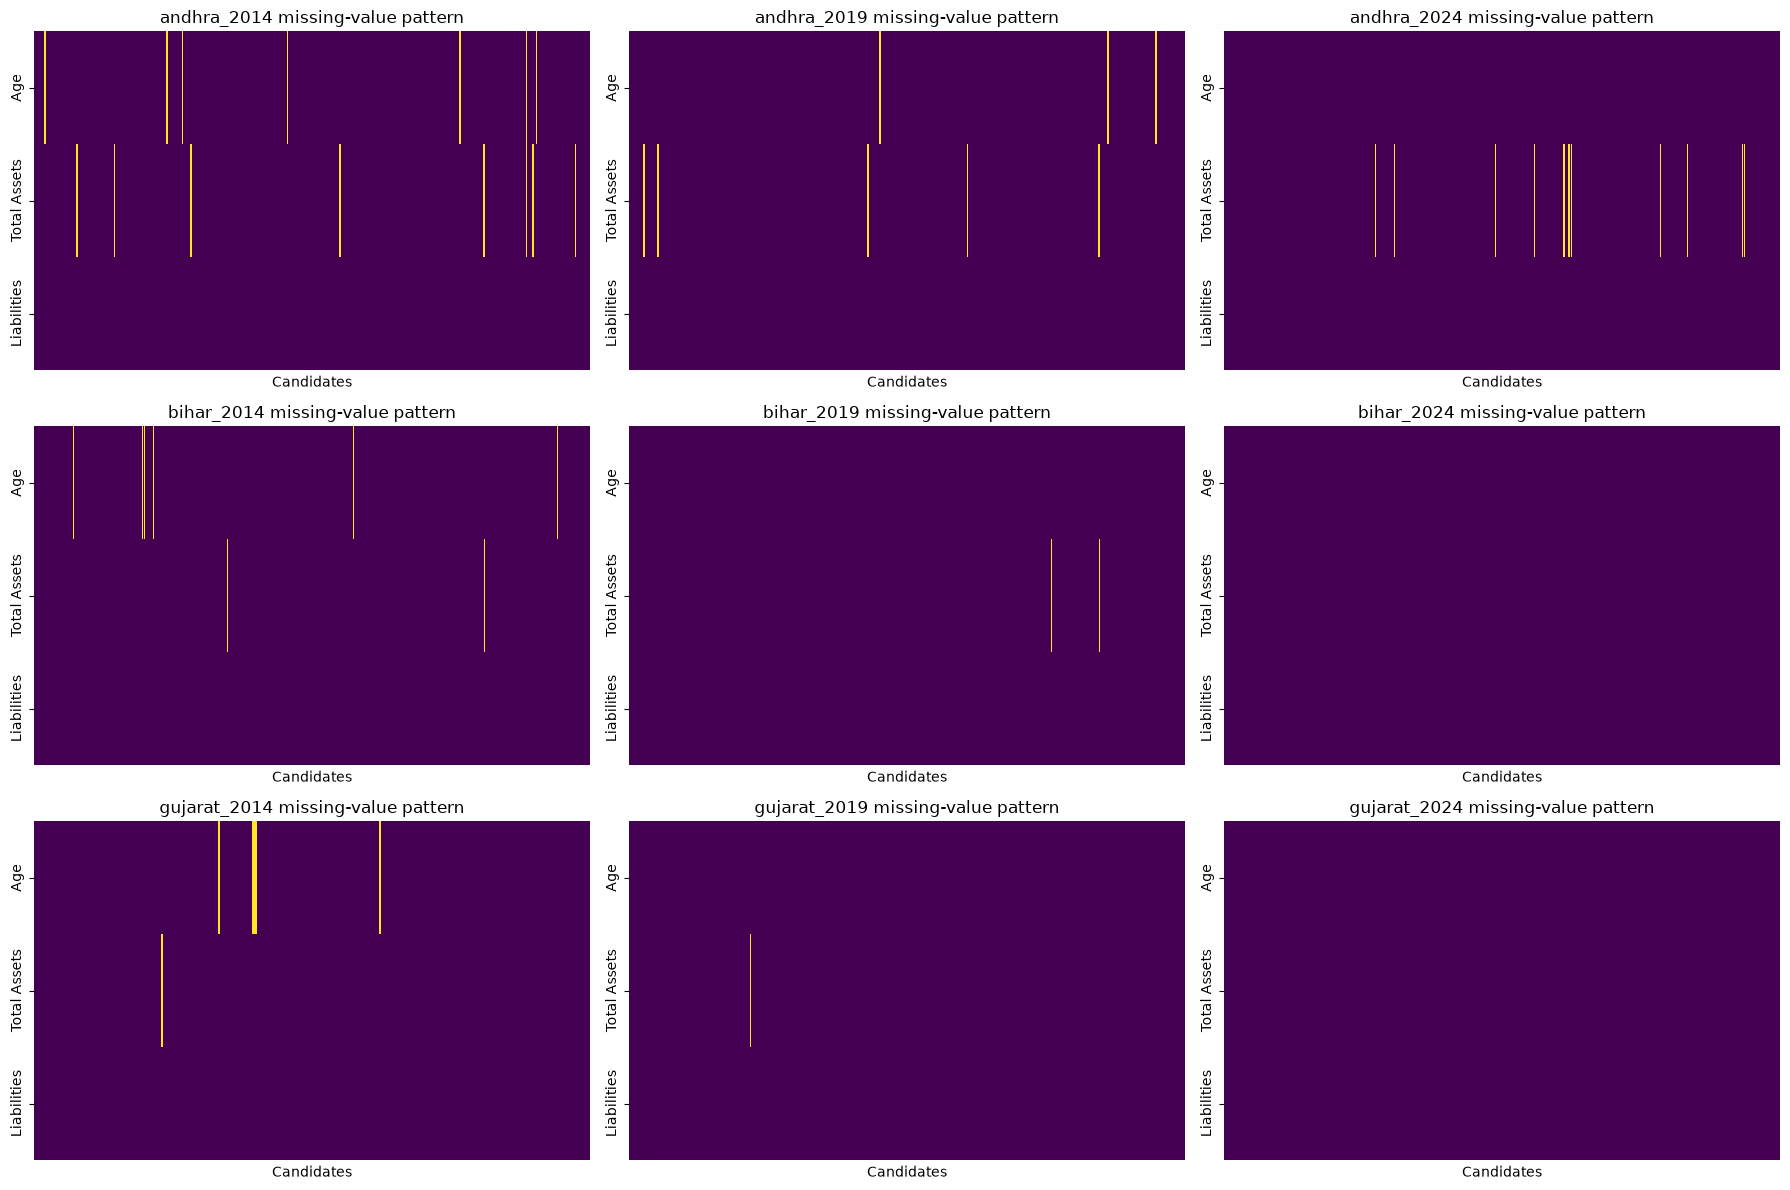

In [45]:
columns_to_show = ["Age", "Total Assets", "Liabilities"]
fig, axes = plt.subplots(3, 3, figsize=(18, 12), squeeze=False,)

for axis in axes.flat:
    axis.set_visible(False)

for axis, (path, df) in zip(axes.flat, cleaned_frames.items()):
    missing_data = pd.DataFrame(index=df.index)

    for column in columns_to_show:
        values = pd.to_numeric(df[column], errors="coerce")
        missing_data[column] = values.isna() | values.eq(-1)

    axis.set_visible(True)
    sns.heatmap(missing_data.T, ax=axis, cmap="viridis", vmin=0, vmax=1,
                cbar=False, xticklabels=False, yticklabels=True,)

    axis.set_title(f"{path} missing-value pattern")
    axis.set_xlabel("Candidates")
    axis.set_ylabel("")

fig.tight_layout()
plt.show()

In [46]:
numeric_cols_to_impute = ["Age", "Total Assets", "Liabilities"]
dropped_frames = {}

for path, df in cleaned_frames.items():
    df_dropped = df.copy()
    all_indices_to_drop = pd.Index([])

    for col in numeric_cols_to_impute:
        # 1. Corrected the column check syntax
        if col not in df_dropped.columns:
            continue

        # Convert to numeric and mask -1 values
        values = pd.to_numeric(df_dropped[col], errors="coerce")
        values = values.mask(values == -1)
        
        # Identify missing indices
        missing_indices = values[values.isna()].index
        missing_count = len(missing_indices)

        if missing_count == 0:
            print(f"{path}: no missing values in {col}")
            continue

        # Collect indices to drop at the end of the column loop
        all_indices_to_drop = all_indices_to_drop.union(missing_indices)

        # 2. Corrected message to state "dropped" instead of "imputed"
        print(
            f"{path}: identified {missing_count} missing/invalid values in {col} "
        )
    
    # 3. Drop all identified rows safely at once
    if not all_indices_to_drop.empty:
        df_dropped = df_dropped.drop(all_indices_to_drop)
        print(f"{path}: Total rows dropped across all columns: {len(all_indices_to_drop)}")

    dropped_frames[path] = df_dropped
    
    # 4. Aligned the save path with your final print statement
    # df_dropped.to_csv(f"interim/cleaned_data/{path}_dropped.csv", index=False)

print(f"Saved {len(dropped_frames)} dropped datasets to interim/cleaned_data/")

andhra_2014: identified 7 missing/invalid values in Age 
andhra_2014: identified 8 missing/invalid values in Total Assets 
andhra_2014: no missing values in Liabilities
andhra_2014: Total rows dropped across all columns: 14
andhra_2019: identified 3 missing/invalid values in Age 
andhra_2019: identified 5 missing/invalid values in Total Assets 
andhra_2019: no missing values in Liabilities
andhra_2019: Total rows dropped across all columns: 8
andhra_2024: no missing values in Age
andhra_2024: identified 11 missing/invalid values in Total Assets 
andhra_2024: no missing values in Liabilities
andhra_2024: Total rows dropped across all columns: 11
bihar_2014: identified 6 missing/invalid values in Age 
bihar_2014: identified 2 missing/invalid values in Total Assets 
bihar_2014: no missing values in Liabilities
bihar_2014: Total rows dropped across all columns: 8
bihar_2019: no missing values in Age
bihar_2019: identified 2 missing/invalid values in Total Assets 
bihar_2019: no missing val

# **5. Preparing data for data visualization**

# Matching candidate names from myneta with winners data

In [47]:
import re
import pandas as pd
from rapidfuzz.distance import JaroWinkler
import itertools
from pathlib import Path

def std_name(name):
    prefixes = r'^(?:(?:Adv|Dr|Mr|Mrs|Ms|Shri|Smt|Prof)\.?\s+)+'
    name = re.sub(prefixes, "", name, flags=re.IGNORECASE)

    lineage_field = r'\s+(?:S/o|D/o|W/o|C/o|H/o|@)\.?\s+.*$'
    name = re.sub(lineage_field, "", name, flags=re.IGNORECASE)

    name = name.split(",", 1)[0]
    name = name.split("(", 1)[0]
    name = name.replace(".", " ")

    words = name.split()
    words = [word.lower() for word in words]
    return " ".join(words)

def names_agree(a, b, threshold=0.80):
    words_a = a.split()
    words_b = b.split()
    if len(words_a) <= len(words_b):
        short, long = words_a, words_b
    else:
        short, long = words_b, words_a

    def words_match(w1, w2):
        if len(w1) == 1 or len(w2) == 1:
            return w1[0] == w2[0]
        return JaroWinkler.similarity(w1, w2) >= threshold

    for perm in itertools.permutations(long, len(short)):
        if all(words_match(s, l) for s, l in zip(short, perm)):
            return True
    return False


def match_candidates(
    election_df,
    winners_df,
    election_name_col="Candidate",
    winner_name_col="Winner Candidate",
):
    election_df = election_df.copy()
    winners_df = winners_df.copy()

    election_df = election_df.set_index("Sno.")

    election_df["_std_name"] = election_df[election_name_col].apply(std_name)
    winners_df["_std_name"] = winners_df[winner_name_col].apply(std_name)

    matches = []

    # Outer loop: winners
    for i, winner_row in winners_df.iterrows():
        name1 = winner_row["_std_name"]

        if not name1:
            continue

        best_match = None
        best_score = 0

        # Inner loop: election candidates
        for j, election_row in election_df.iterrows():
            name2 = election_row["_std_name"]

            if not name2:
                continue

            if names_agree(name1, name2):
                score = JaroWinkler.similarity(name1, name2)

                if score > best_score:
                    best_score = score
                    best_match = {
                        "winner_candidate": winner_row[winner_name_col],
                        "winner_of_constituency": winner_row["Constituency"],
                        "election_candidate": election_row[election_name_col],
                        "similarity": score,
                        "party": winner_row.get("Winner Party", None),
                        "winner_index": i,
                        "election_index": j
                    }

        if best_match is not None:
            matches.append(best_match)

    return pd.DataFrame(matches)

In [48]:
df = pd.read_csv("raw/wikipedia_loksabha_winners_2014_2019_2024_normalized_20-09-2026.csv")

In [49]:
andhra_14_winners = df[(df["State"]=="Andhra Pradesh")&(df["Election Year"]==2014)]
andhra_14 = pd.read_csv("interim/cleaned_data/andhra_2014_dropped.csv")
matching_andhra_14 = match_candidates(andhra_14, andhra_14_winners)
matching_andhra_14

,winner_candidate,winner_of_constituency,election_candidate,similarity,party,winner_index,election_index
0,Kothapalli Geetha,Araku,Kothapalli Geetha,1.000000,YSRCP,0,147
1,Ram Mohan Naidu Kinjarapu,Srikakulam,Rammohannaidu Kinjarapu,0.930609,TDP,1,235
2,Ashok Gajapathi Raju,Vizianagaram,Ashok Gajapathi Raju Pusapati,0.937931,TDP,2,16
3,Kambhampati Hari Babu,Visakhapatnam,Kambhampati Hari Babu,1.000000,BJP,3,70
4,Muttamsetti Srinivasa Rao,Anakapalle,Muttamsetti Srinivasa Rao,1.000000,TDP,4,186
5,Thota Narasimham,Kakinada,Thota Venkata Narasimham,0.895833,TDP,5,283
6,Pandula Ravindra Babu,Amalapuram,Pandula Ravindra Babu,1.000000,TDP,6,210
7,Murali Mohan,Rajahmundry,Murali Mohan Maganti,0.920000,TDP,7,184
8,Gokaraju Ganga Raju,Narasapuram,Gokaraju Ganga Raju,1.000000,BJP,8,88
9,Maganti Venkateswara Rao,Eluru,Venkateswara Rao Maganti,0.789683,TDP,9,310


In [50]:
# Check Sno. for Y. S. Avinash Reddy
for _, row in andhra_14.iterrows():
    if names_agree(std_name(row["Candidate"]), "y s avinash reddy"):
        print(row["Candidate"], row["Sno."])

Avinash Reddy Yeduguri Sandinti 18
Shanthi Reddy 260
Yeluri Srilatha 328


In [51]:
matching_andhra_14.loc[matching_andhra_14["winner_candidate"] == "Y. S. Avinash Reddy", "election_candidate"] = "Avinash Reddy Yeduguri Sandinti"
matching_andhra_14.loc[matching_andhra_14["winner_candidate"] == "Y. S. Avinash Reddy", "election_index"] = 18
matching_andhra_14

,winner_candidate,winner_of_constituency,election_candidate,similarity,party,winner_index,election_index
0,Kothapalli Geetha,Araku,Kothapalli Geetha,1.000000,YSRCP,0,147
1,Ram Mohan Naidu Kinjarapu,Srikakulam,Rammohannaidu Kinjarapu,0.930609,TDP,1,235
2,Ashok Gajapathi Raju,Vizianagaram,Ashok Gajapathi Raju Pusapati,0.937931,TDP,2,16
3,Kambhampati Hari Babu,Visakhapatnam,Kambhampati Hari Babu,1.000000,BJP,3,70
4,Muttamsetti Srinivasa Rao,Anakapalle,Muttamsetti Srinivasa Rao,1.000000,TDP,4,186
5,Thota Narasimham,Kakinada,Thota Venkata Narasimham,0.895833,TDP,5,283
6,Pandula Ravindra Babu,Amalapuram,Pandula Ravindra Babu,1.000000,TDP,6,210
7,Murali Mohan,Rajahmundry,Murali Mohan Maganti,0.920000,TDP,7,184
8,Gokaraju Ganga Raju,Narasapuram,Gokaraju Ganga Raju,1.000000,BJP,8,88
9,Maganti Venkateswara Rao,Eluru,Venkateswara Rao Maganti,0.789683,TDP,9,310


In [52]:
andhra_19_winners = df[(df["State"]=="Andhra Pradesh")&(df["Election Year"]==2019)]
andhra_19 = pd.read_csv("interim/cleaned_data/andhra_2019_dropped.csv")
matching_andhra_19 = match_candidates(andhra_19, andhra_19_winners)
matching_andhra_19

,winner_candidate,winner_of_constituency,election_candidate,similarity,party,winner_index,election_index
0,Goddeti Madhavi,Araku (ST),Goddeti Madhavi,1.000000,YSRCP,91,97
1,Kinjarapu Ram Mohan Naidu,Srikakulam,Rammohannaidu Kinjarapu,0.721678,TDP,92,246
2,Bellana Chandra Sekhar,Vizianagaram,Bellana Chandra Sekhar,1.000000,YSRCP,93,32
3,M. V. V. Satyanarayana,Visakhapatnam,M V V Satyanarayana,1.000000,YSRCP,94,163
4,Beesetti Venkata Satyavathi,Anakapalle,Dr Beesetti Venkata Satyavathi,1.000000,YSRCP,95,78
5,Vanga Geetha,Kakinada,Vanga Geetha Viswanatham,0.900000,YSRCP,96,296
6,Chinta Anuradha,Amalapuram (SC),Chinta Anuradha,1.000000,YSRCP,97,55
7,Margani Bharat,Rajahmundry,Margani Bharat Ram,0.955556,YSRCP,98,178
8,Raghu Rama Krishna Raju,Narasapuram,Kanumuru Raghu Rama Krishna Raju,0.761322,YSRCP,99,141
9,Kotagiri Sridhar,Eluru,K T Sreedhar,0.622685,YSRCP,100,132


In [53]:
andhra_24_winners = df[(df["State"]=="Andhra Pradesh")&(df["Election Year"]==2024)]
andhra_24 = pd.read_csv("interim/cleaned_data/andhra_2024_dropped.csv")
matching_andhra_24 = match_candidates(andhra_24, andhra_24_winners)
matching_andhra_24

,winner_candidate,winner_of_constituency,election_candidate,similarity,party,winner_index,election_index
0,Gumma Thanuja Rani,Araku (ST),Gumma Thanuja Rani,1.000000,YSRCP,182,176
1,K. Ram Mohan Naidu,Srikakulam,Kinjarapu Rammohan Naidu,0.751103,TDP,183,223
2,Appala Naidu Kalisetti,Vizianagaram,Appalanaidu Kalisetti,0.962338,TDP,184,33
3,C. M. Ramesh,Anakapalle,C M Ramesh,1.000000,BJP,186,96
4,Tangella Uday Srinivas,Kakinada,Tangella Uday Srinivas,1.000000,Janasena Party,187,392
5,Ganti Harish Madhur,Amalapuram (SC),G M Harish,0.657018,TDP,188,150
6,Daggubati Purandeswari,Rajahmundry,Daggubati Purandheshwari,0.983333,BJP,189,116
7,Bhupathi Srinivasa Varma,Narasapuram,Bhupathi Raju Srinivasa Varma,0.907184,BJP,190,71
8,Putta Mahesh Kumar,Eluru,Putta Mahesh Kumar,1.000000,TDP,191,337
9,Vallabhaneni Balashowry,Machilipatnam,Balashowry Vallabhaneni,0.620083,Janasena Party,192,53


In [54]:
bihar_24_winners = df[(df["State"] == "Bihar") & (df["Election Year"] == 2024)]
bihar_24 = pd.read_csv("interim/cleaned_data/bihar_2024_dropped.csv")
matching_bihar_24 = match_candidates(bihar_24, bihar_24_winners)
matching_bihar_24

,winner_candidate,winner_of_constituency,election_candidate,similarity,party,winner_index,election_index
0,Sunil Kumar,Valmiki Nagar,Sunil Kumar,1.000000,JD(U),207,445
1,Sanjay Jaiswal,Paschim Champaran,Dr Sanjay Jaiswal,1.000000,BJP,208,129
2,Radha Mohan Singh,Purvi Champaran,Radha Mohan Singh,1.000000,BJP,209,312
3,Lovely Anand,Sheohar,Lovely Anand,1.000000,JD(U),210,202
4,Devesh Chandra Thakur,Sitamarhi,Devesh Chandra Thakur,1.000000,JD(U),211,105
5,Ashok Kumar Yadav,Madhubani,Ashok Kumar Yadav,1.000000,BJP,212,58
6,Ramprit Mandal,Jhanjharpur,Ramprit Mandal,1.000000,JD(U),213,356
7,Dileshwar Kamait,Supaul,Dileshwar Kamait,1.000000,JD(U),214,113
8,Pradeep Kumar Singh,Araria,Pradeep Kumar Singh,1.000000,BJP,215,295
9,Mohammad Jawed,Kishanganj,Mohammad Jawed,1.000000,INC,216,235


In [55]:
# Check Sno. for Lalan Singh
for _, row in bihar_24.iterrows():
    if names_agree(std_name(row["Candidate"]), "lalan singh"):
        print(row["Candidate"], row["Sno."])

Lal Badsah Singh 199
Rajiv Ranjan Singh Alias Lalan Singh 335


In [56]:
matching_bihar_24.loc[matching_bihar_24["winner_candidate"] == "Lalan Singh", "election_candidate"] = "Rajiv Ranjan Singh Alias Lalan Singh"
matching_bihar_24.loc[matching_bihar_24["winner_candidate"] == "Lalan Singh", "election_index"] = 335
matching_bihar_24

,winner_candidate,winner_of_constituency,election_candidate,similarity,party,winner_index,election_index
0,Sunil Kumar,Valmiki Nagar,Sunil Kumar,1.000000,JD(U),207,445
1,Sanjay Jaiswal,Paschim Champaran,Dr Sanjay Jaiswal,1.000000,BJP,208,129
2,Radha Mohan Singh,Purvi Champaran,Radha Mohan Singh,1.000000,BJP,209,312
3,Lovely Anand,Sheohar,Lovely Anand,1.000000,JD(U),210,202
4,Devesh Chandra Thakur,Sitamarhi,Devesh Chandra Thakur,1.000000,JD(U),211,105
5,Ashok Kumar Yadav,Madhubani,Ashok Kumar Yadav,1.000000,BJP,212,58
6,Ramprit Mandal,Jhanjharpur,Ramprit Mandal,1.000000,JD(U),213,356
7,Dileshwar Kamait,Supaul,Dileshwar Kamait,1.000000,JD(U),214,113
8,Pradeep Kumar Singh,Araria,Pradeep Kumar Singh,1.000000,BJP,215,295
9,Mohammad Jawed,Kishanganj,Mohammad Jawed,1.000000,INC,216,235


In [57]:
for i in list(bihar_24["Candidate"]):
    if names_agree(std_name(i), "abhay kushwaha"):
        print(i)

A K Singh


In [58]:
bihar_19_winners = df[(df["State"] == "Bihar") & (df["Election Year"] == 2019)]
bihar_19 = pd.read_csv("interim/cleaned_data/bihar_2019_dropped.csv")
matching_bihar_19 = match_candidates(bihar_19, bihar_19_winners)
matching_bihar_19

,winner_candidate,winner_of_constituency,election_candidate,similarity,party,winner_index,election_index
0,Baidyanath Prasad Mahto,Valmiki Nagar,Baidyanath Prasad Mahto,1.000000,JD(U),116,81
1,Sanjay Jaiswal,Paschim Champaran,Sanjay Jaiswal,1.000000,BJP,117,156
2,Radha Mohan Singh,Purvi Champaran,Radha Mohan Singh,1.000000,BJP,118,352
3,Rama Devi,Sheohar,Rama Devi,1.000000,BJP,119,411
4,Sunil Kumar Pintu,Sitamarhi,Sunil Kumar,0.929412,JD(U),120,543
5,Ashok Kumar Yadav,Madhubani,Ashok Kumar Yadav,1.000000,BJP,121,75
6,Ramprit Mandal,Jhanjharpur,Ramprit Mandal,1.000000,JD(U),122,429
7,Dileshwar Kamait,Supaul,Dileshwar Kamait,1.000000,JD(U),123,137
8,Pradeep Kumar Singh,Araria,Pradeep Kumar Singh,1.000000,BJP,124,332
9,Mohammad Jawed,Kishanganj,Mohammad Jawed,1.000000,INC,125,154


In [59]:
bihar_14_winners = df[(df["State"] == "Bihar") & (df["Election Year"] == 2014)]
bihar_14 = pd.read_csv("interim/cleaned_data/bihar_2014_dropped.csv")
matching_bihar_14 = match_candidates(bihar_14, bihar_14_winners)
matching_bihar_14

,winner_candidate,winner_of_constituency,election_candidate,similarity,party,winner_index,election_index
0,Satish Chandra Dubey,Valmiki Nagar,Satish Dubey,0.920000,BJP,25,486
1,Sanjay Jaiswal,Paschim Champaran,Sanjay Jayaswal,0.943663,BJP,26,135
2,Radha Mohan Singh,Purvi Champaran,Radha Mohan Singh,1.000000,BJP,27,382
3,Rama Devi,Sheohar,Rama Devi,1.000000,BJP,28,431
4,Ram Kumar Sharma,Sitamarhi,Ram Kumar Sharma,1.000000,Rashtriya Lok Samta Party,29,424
5,Hukmdev Narayan Yadav,Madhubani,Hukum Deo Narayan Yadav,0.900121,BJP,30,166
6,Birendra Chaudhary,Jhanjharpur,Bijendra Chaudhary,0.938998,BJP,31,76
7,Ranjeet Ranjan,Supaul,Ranjeet Ranjan,1.000000,INC,32,451
8,Taslimuddin,Araria,Taslim Uddin,0.983333,RJD,33,566
9,Tariq Anwar,Katihar,Md Tariq Anwar,0.837662,NCP,35,271


In [60]:
gujarat_14_winners = df[(df["State"] == "Gujarat") & (df["Election Year"] == 2014)]
gujarat_14 = pd.read_csv("interim/cleaned_data/gujarat_2014_dropped.csv")
matching_gujarat_14 = match_candidates(gujarat_14, gujarat_14_winners)
matching_gujarat_14

,winner_candidate,winner_of_constituency,election_candidate,similarity,party,winner_index,election_index
0,Vinodbhai Chavda,Kachchh,Chavda Vinod Lakhmashi,0.694264,BJP,65,44
1,Haribhai Chaudhary,Banaskantha,Harilal Ranchodbhai Chauhan,0.844227,BJP,66,82
2,Liladhar Vaghela,Patan,Vaghela Liladharbhai Khodaji,0.711310,BJP,67,314
3,Jayshreeben Patel,Mahesana,Patel Jayshreeben Kanubhai,0.747360,BJP,68,194
4,Dipsinh Rathod,Sabarkantha,Rathod Dipsinh Shankarsinh,0.679487,BJP,69,236
5,L. K. Advani,Gandhinagar,Lal Krishna Advani,0.746667,BJP,70,118
6,Paresh Rawal,Ahmedabad East,Paresh Dahyalal Rawal,0.880952,BJP,71,173
7,Kirit Solanki,Ahmedabad West,Solanki Kiritbhai Premjibhai,0.667582,BJP,72,67
8,Devajibhai Fatepara,Surendranagar,Fatepara Devajibhai Govindbhai,0.719883,BJP,73,69
9,Mohan Kundariya,Rajkot,Mohanbhai Kalyanjibhai Kundariya,0.641667,BJP,74,149


In [61]:
gujarat_19_winners = df[(df["State"] == "Gujarat") & (df["Election Year"] == 2019)]
gujarat_19 = pd.read_csv("interim/cleaned_data/gujarat_2019_dropped.csv")
matching_gujarat_19 = match_candidates(gujarat_19, gujarat_19_winners)
matching_gujarat_19

,winner_candidate,winner_of_constituency,election_candidate,similarity,party,winner_index,election_index
0,Vinodbhai Chavda,Kachchh,Chavda Vinod Lakhamshi,0.694264,BJP,156,70
1,Parbatbhai Patel,Banaskantha,Parbatbhai Patel,1.000000,BJP,157,207
2,Shardaben Patel,Mahesana,Shardaben Anilbhai Patel,0.898333,BJP,159,300
3,Dipsinh Rathod,Sabarkantha,Rathod Dipsinh Shankarsinh,0.679487,BJP,160,270
4,Amit Shah,Gandhinagar,Amit Shah,1.000000,BJP,161,10
5,Hasmukh Patel,Ahmedabad East,Patel Hasmukhbhai Somabhai,0.705128,BJP,162,223
6,Kirit Solanki,Ahmedabad West,Solanki Kiritbhai,0.679556,BJP,163,99
7,Mahendra Munjapara,Surendranagar,Mahendrabhai Munjpara,0.938095,BJP,164,169
8,Mohan Kundariya,Rajkot,Kundaria Mohanbhai,0.629966,BJP,165,160
9,Rameshbhai Dhaduk,Porbandar,Rameshbhai Dhaduk,1.000000,BJP,166,259


In [62]:
for _, row in gujarat_19.iterrows():
    if names_agree(std_name(row["Candidate"]), std_name("Rajesh Chudasama")):
        print(row["Candidate"], row["Sno."])

Chudasama Rajeshbhai Naranbhai 73
Rakeshbhai 257


In [63]:
matching_gujarat_19.loc[matching_gujarat_19["winner_candidate"] == "Rajesh Chudasama", "election_candidate"] = "Chudasama Rajeshbhai Naranbhai"
matching_gujarat_19.loc[matching_gujarat_19["winner_candidate"] == "Rajesh Chudasama", "election_index"] = 73
matching_gujarat_19

,winner_candidate,winner_of_constituency,election_candidate,similarity,party,winner_index,election_index
0,Vinodbhai Chavda,Kachchh,Chavda Vinod Lakhamshi,0.694264,BJP,156,70
1,Parbatbhai Patel,Banaskantha,Parbatbhai Patel,1.000000,BJP,157,207
2,Shardaben Patel,Mahesana,Shardaben Anilbhai Patel,0.898333,BJP,159,300
3,Dipsinh Rathod,Sabarkantha,Rathod Dipsinh Shankarsinh,0.679487,BJP,160,270
4,Amit Shah,Gandhinagar,Amit Shah,1.000000,BJP,161,10
5,Hasmukh Patel,Ahmedabad East,Patel Hasmukhbhai Somabhai,0.705128,BJP,162,223
6,Kirit Solanki,Ahmedabad West,Solanki Kiritbhai,0.679556,BJP,163,99
7,Mahendra Munjapara,Surendranagar,Mahendrabhai Munjpara,0.938095,BJP,164,169
8,Mohan Kundariya,Rajkot,Kundaria Mohanbhai,0.629966,BJP,165,160
9,Rameshbhai Dhaduk,Porbandar,Rameshbhai Dhaduk,1.000000,BJP,166,259


In [64]:
for _, row in gujarat_19.iterrows():
    if names_agree(std_name(row["Candidate"]), std_name("C. R. Patil")):
        print(row["Candidate"], row["Sno."])

Chandansinh 45
Chandraben 96
Patil Chandrakant 239
Rakeshbhai 257
Reshma Patel 280
Rita Captain 281


In [65]:
matching_gujarat_19.loc[matching_gujarat_19["winner_candidate"] == "C. R. Patil", "election_candidate"] = "Patil Chandrakant"
matching_gujarat_19.loc[matching_gujarat_19["winner_candidate"] == "C. R. Patil", "election_index"] = 239
matching_gujarat_19

,winner_candidate,winner_of_constituency,election_candidate,similarity,party,winner_index,election_index
0,Vinodbhai Chavda,Kachchh,Chavda Vinod Lakhamshi,0.694264,BJP,156,70
1,Parbatbhai Patel,Banaskantha,Parbatbhai Patel,1.000000,BJP,157,207
2,Shardaben Patel,Mahesana,Shardaben Anilbhai Patel,0.898333,BJP,159,300
3,Dipsinh Rathod,Sabarkantha,Rathod Dipsinh Shankarsinh,0.679487,BJP,160,270
4,Amit Shah,Gandhinagar,Amit Shah,1.000000,BJP,161,10
5,Hasmukh Patel,Ahmedabad East,Patel Hasmukhbhai Somabhai,0.705128,BJP,162,223
6,Kirit Solanki,Ahmedabad West,Solanki Kiritbhai,0.679556,BJP,163,99
7,Mahendra Munjapara,Surendranagar,Mahendrabhai Munjpara,0.938095,BJP,164,169
8,Mohan Kundariya,Rajkot,Kundaria Mohanbhai,0.629966,BJP,165,160
9,Rameshbhai Dhaduk,Porbandar,Rameshbhai Dhaduk,1.000000,BJP,166,259


In [66]:
gujarat_24_winners = df[(df["State"] == "Gujarat") & (df["Election Year"] == 2024)]
gujarat_24 = pd.read_csv("interim/cleaned_data/gujarat_2024_dropped.csv")
matching_gujarat_24 = match_candidates(gujarat_24, gujarat_24_winners)
matching_gujarat_24

,winner_candidate,winner_of_constituency,election_candidate,similarity,party,winner_index,election_index
0,Vinodbhai Chavda,Kachchh,Chavda Vinod Lakhamshi,0.694264,BJP,247,59
1,Geni Thakor,Banaskantha,Geniben Nagaji Thakor,0.610390,INC,248,89
2,Bharatsinhji Dabhi,Patan,Dabhi Bharatsinhji Shankarji,0.732804,BJP,249,64
3,Haribhai Patel,Mahesana,Haribhai Patel,1.000000,BJP,250,95
4,Shobhanaben Baraiya,Sabarkantha,Shobhanaben Mahendrasinh Baraiya,0.887171,BJP,251,230
5,Amit Shah,Gandhinagar,Amit Shah,1.000000,BJP,252,9
6,Hasmukh Patel,Ahmedabad East,Hasmukhbhai Patel,0.937557,BJP,253,98
7,Dinesh Makwana,Ahmedabad West,Dineshbhai Makwana,0.898413,BJP,254,80
8,Chandubhai Shihora,Surendranagar,Chandubhai Chhaganbhai Shihora,0.886667,BJP,255,51
9,Parshottam Rupala,Rajkot,Parshottambhai Rupala,0.926611,BJP,256,185


# Matching candidates across years to find recontesting candidates

In [67]:
def match_repeat_candidates(
    year1_df,
    year2_df,
    name_col="Candidate",
    threshold=0.85
):
    results = []

    a = year1_df.copy()
    b = year2_df.copy()

    a["_std_name"] = a[name_col].fillna("").apply(std_name)
    b["_std_name"] = b[name_col].fillna("").apply(std_name)

    for i, row1 in a.iterrows():
        name1 = row1["_std_name"]
        age1 = row1['Age']
        if not name1:
            continue

        candidates = []

        for j, row2 in b.iterrows():
            name2 = row2["_std_name"]
            age2 = row2['Age']
            if not name2 or not names_agree(name1, name2) or not (4<=age2-age1<=5):
                continue

            score = JaroWinkler.similarity(name1, name2)

            if score < threshold:
                continue

            candidates.append({
                "candidate_2014": row1[name_col],
                "candidate_2019": row2[name_col],
                "similarity": score,
                "index_prev": row1['Sno.'],
                "index_cur": row2['Sno.']
            })

        if candidates:
            best = max(
                candidates,
                key=lambda x: x["similarity"]
            )
            results.append(best)

    return pd.DataFrame(results)

In [68]:
def flag_recontesters(df_prev, df_curr, name_col="Candidate", threshold=0.70):
    # 1. Get the raw matches using your existing function
    matches = match_repeat_candidates(df_prev, df_curr, name_col=name_col, threshold=threshold)
    
    # Safety check: if no matches exist at all
    if matches.empty:
        df_curr["Recontester"] = -1
        return df_curr

    # 2. Create the 1:1 mapping, resolving duplicates by highest similarity
    mapping = (
        matches
        .sort_values("similarity", ascending=False)
        .drop_duplicates("index_cur")
        .set_index("index_cur")["index_prev"]
    )
    
    # 3. Map Sno. of current year candidates to Sno. of previous year
    df_curr["Recontester"] = df_curr["Sno."].map(mapping).fillna(-1).astype(int)
    
    return df_curr

In [69]:
andhra_19 = flag_recontesters(andhra_14, andhra_19)
andhra_24 = flag_recontesters(andhra_19, andhra_24)
bihar_19 = flag_recontesters(bihar_14, bihar_19)
bihar_24 = flag_recontesters(bihar_19, bihar_24)
gujarat_19 = flag_recontesters(gujarat_14, gujarat_19)
gujarat_24 = flag_recontesters(gujarat_19, gujarat_24)

**Adding new columns to data**

In [70]:
def process_election_data(df, matching_df):
    df = df.copy()

    # Map constituency by election_index (Sno.)
    constituency_map = matching_df.set_index("election_index")["winner_of_constituency"]
    
    # Identify which candidates won using Sno.
    winning_snos = matching_df["election_index"].unique()
    
    # Mark winner status and map constituency using Sno.
    df["winner"] = df["Sno."].isin(winning_snos)
    df["constituency"] = df["Sno."].map(constituency_map).fillna("")

    return df

In [71]:
datasets = [
    (andhra_14, matching_andhra_14, "andhra_2014"),
    (andhra_19, matching_andhra_19, "andhra_2019"),
    (andhra_24, matching_andhra_24, "andhra_2024"),
    (bihar_14, matching_bihar_14, "bihar_2014"),
    (bihar_19, matching_bihar_19, "bihar_2019"),
    (bihar_24, matching_bihar_24, "bihar_2024"),
    (gujarat_14, matching_gujarat_14, "gujarat_2014"),
    (gujarat_19, matching_gujarat_19, "gujarat_2019"),
    (gujarat_24, matching_gujarat_24, "gujarat_2024"),
]

processed_dfs = {}
for df, matching_df, name in datasets:
    processed_dfs[name] = process_election_data(df, matching_df)

In [72]:
# for name in processed_dfs:
#     dataframe = processed_dfs[name]
#     dataframe.to_csv(f"clean/{name}.csv", index=False)

# Rechecking dtypes after reading the file back

In [73]:
import pandas as pd
files = [
    "andhra_2014", "andhra_2019", "andhra_2024", 
    "bihar_2014",  "bihar_2019", "bihar_2024", 
    "gujarat_2014", "gujarat_2019", "gujarat_2024"
]
data = []
for name in files:
    data.append(pd.read_csv(f"clean/{name}.csv").dtypes)
df = pd.DataFrame(data, index=[i for i in files])
df['Recontester'] = df['Recontester'].fillna("Column Not there")
df

,Sno.,Candidate,Party,Criminal Cases,Education,Age,Total Assets,Liabilities,winner,constituency,Recontester
andhra_2014,int64,str,str,int64,str,int64,int64,int64,bool,str,Column Not there
andhra_2019,int64,str,str,int64,str,int64,int64,int64,bool,str,int64
andhra_2024,int64,str,str,int64,str,int64,int64,int64,bool,str,int64
bihar_2014,int64,str,str,int64,str,int64,int64,int64,bool,str,Column Not there
bihar_2019,int64,str,str,int64,str,int64,int64,int64,bool,str,int64
bihar_2024,int64,str,str,int64,str,int64,int64,int64,bool,str,int64
gujarat_2014,int64,str,str,int64,str,int64,int64,int64,bool,str,Column Not there
gujarat_2019,int64,str,str,int64,str,int64,int64,int64,bool,str,int64
gujarat_2024,int64,str,str,int64,str,int64,int64,int64,bool,str,int64


In [74]:
CLEANED_DATA_DIR = Path("clean")

column_info = {
    "Sno.": {
        "Unit": "Serial number",
        "Source": "Myneta dataset",
        "Allowed Range": "Positive integers"
    },
    "Candidate": {
        "Unit": "N/A",
        "Source": "Myneta dataset",
        "Allowed Range": "Non-empty candidate names"
    },
    "Party": {
        "Unit": "N/A",
        "Source": "Myneta dataset",
        "Allowed Range": "Valid political party names or IND"
    },
    "Criminal Cases": {
        "Unit": "Number of cases",
        "Source": "Myneta dataset",
        "Allowed Range": "Non-negative integers"
    },
    "Education": {
        "Unit": "N/A",
        "Source": "Myneta dataset",
        "Allowed Range": "Valid education categories"
    },
    "Age": {
        "Unit": "Years",
        "Source": "Myneta dataset",
        "Allowed Range": "21 or above"
    },
    "Total Assets": {
        "Unit": "INR (₹)",
        "Source": "Myneta dataset",
        "Allowed Range": "Non-negative values"
    },
    "Liabilities": {
        "Unit": "INR (₹)",
        "Source": "Myneta dataset",
        "Allowed Range": "Non-negative values"
    },
    "Recontester": {
        "Unit": "Serial number",
        "Source": "Derived during preprocessing",
        "Allowed Range": "-1 or valid previous-election serial number"
    },
    "winner": {
        "Unit": "Boolean",
        "Source": "Winners dataset",
        "Allowed Range": "True or False"
    },
    "constituency": {
        "Unit": "N/A",
        "Source": "Myneta dataset",
        "Allowed Range": "Empty or valid constituency name (for winners only)"
    }
}

metadata = []

for file_path in CLEANED_DATA_DIR.glob("*.csv"):

    df = pd.read_csv(file_path)

    for column in df.columns:

        info = column_info.get(column, {})

        metadata.append({
            "File": file_path.name,
            "Column": column,
            "Dtype": str(df[column].dtype),
            "Unit": info.get("Unit", "Not specified"),
            "Source": info.get("Source", "Not specified"),
            "Allowed Range": info.get("Allowed Range", "Not specified")
        })

metadata_df = pd.DataFrame(metadata)

# metadata_df.to_csv(
#     "clean/cleaned_data_dictionary.csv",
#     index=False
# )

print("Cleaned data dictionary created successfully!")

Cleaned data dictionary created successfully!


# **6. Outlier Detection**

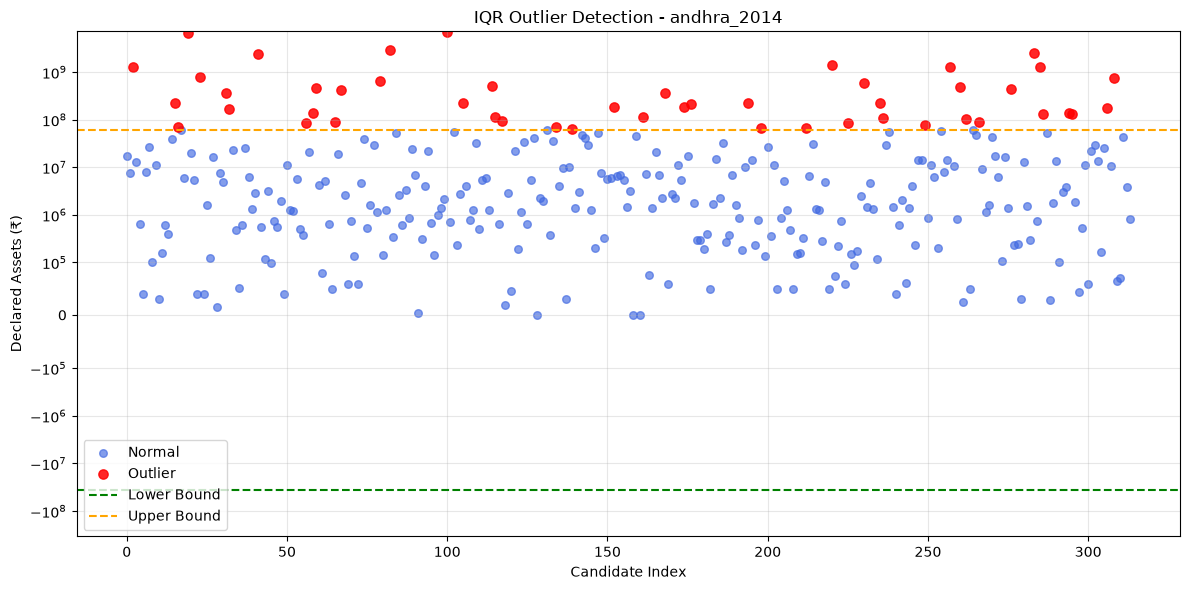


FILE: andhra_2014.csv
Total candidates: 314
Outliers detected: 48
Lower bound: -36,607,870.25
Upper bound: 62,069,783.75

Detected Outliers:
                                             Candidate  Total Assets
                                Adala Prabhakara Reddy    1282585640
                                      Avinash Devineni     228035761
                       Avinash Reddy Yeduguri Sandinti      70480623
                               Ayodhya Rami Reddy Alla    6543381756
                               Balashowry Vallabhaneni     794017805
                         Boddu Venkata Ramana Chowdary     356200864
                               Bolisetti Satyanarayana     166746916
                                          Butta Renuka    2426240513
                                Daggubati Purandeswari      84841544
                                        Dande Yugander     135654625
                      Darisi Veera Venkata Pavan Kumar     464329120
                              

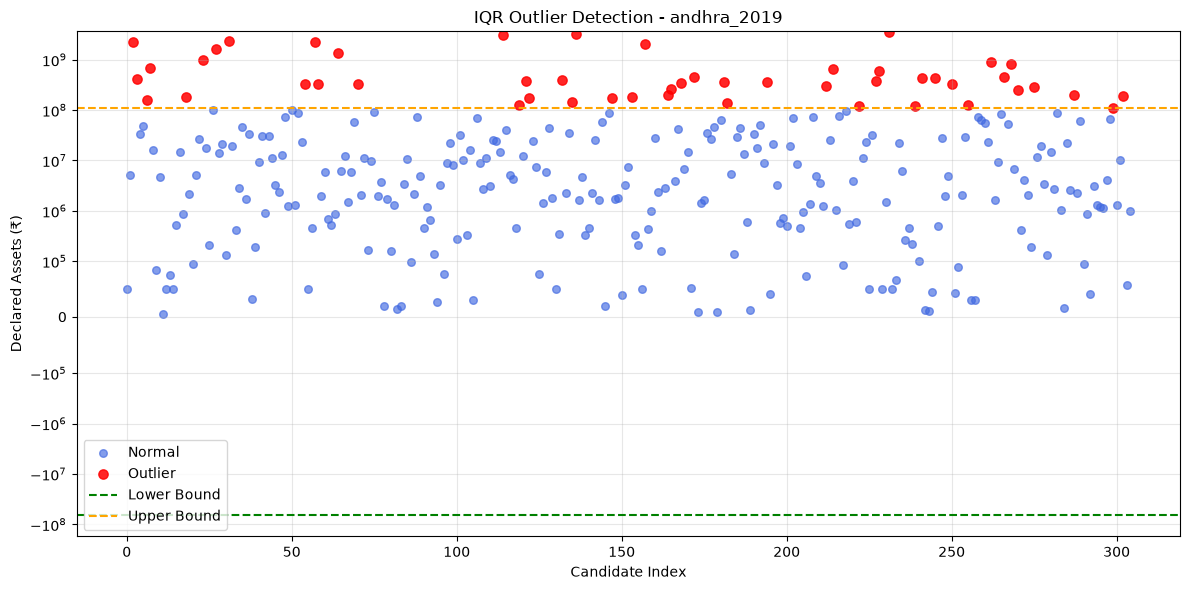


FILE: andhra_2019.csv
Total candidates: 305
Outliers detected: 49
Lower bound: -63,787,000.00
Upper bound: 107,812,200.00

Detected Outliers:
                       Candidate  Total Assets
          Adala Prabhakara Reddy    2211663364
               Adari Anand Kumar     410547212
                  Ahmed Ali Khan     158831414
             Akula Satyanarayana     673924565
   Ashok Gajapathi Raju Pusapati     183534582
         Balashowry Vallabhaneni     990575840
               Beeda Masthan Rao    1654392880
             Bharat Mathukumilli    2325373550
         Chintala Partha Sarathi     335308506
               D A Sathya Prabha    2204833211
          Daggubati Purandeswari     324038450
                   Dileep Kilaru    1369017847
                   Sanjeev Kumar     325914387
                   Jayadev Galla    3051485242
                 Jesudasu Seelam     126397634
 Juturu Chinna Reddy Pavan Reddy     373887429
       Jyothula Venkateswara Rao     173451539
          K

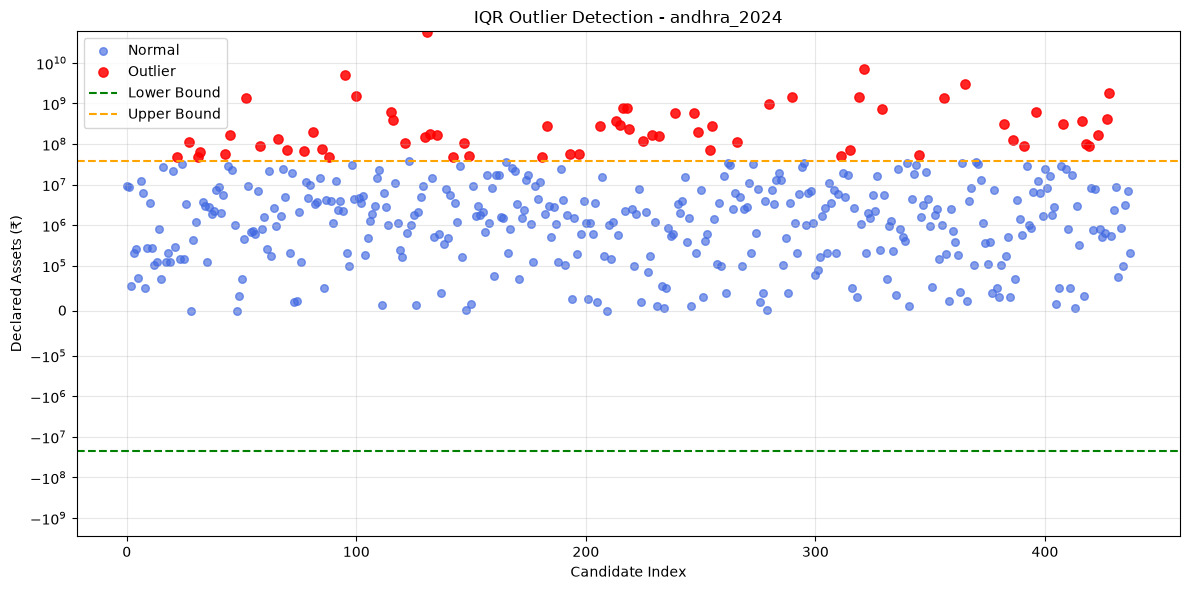


FILE: andhra_2024.csv
Total candidates: 438
Outliers detected: 66
Lower bound: -22,762,723.75
Upper bound: 38,683,206.25

Detected Outliers:
                       Candidate  Total Assets
Ambica G Lakshminarayana Valmiki      47540056
            Anil Kumar Poluboina     110667086
               Appala Raju Nammi      47810500
           Appalanaidu Kalisetti      62365187
               B A Samad Shaheen      56387631
               B K Parthasarathi     168959895
         Balashowry Vallabhaneni    1337214564
Bastipati Nagaraju Panchalingala      90176000
                 Bhargav Valluru     129653183
   Bhupathi Raju Srinivasa Varma      71664809
         Bommanaboina Vsr Murthy      67643000
            Botcha Jhansilakshmi     197603661
              Budi Mutyala Naidu      73992295
                   Buraga Ratnam      47013655
                      C M Ramesh    4976024996
            Chalamalasetty Sunil    1499962589
        Daggubati Purandheshwari     625041146
          Da

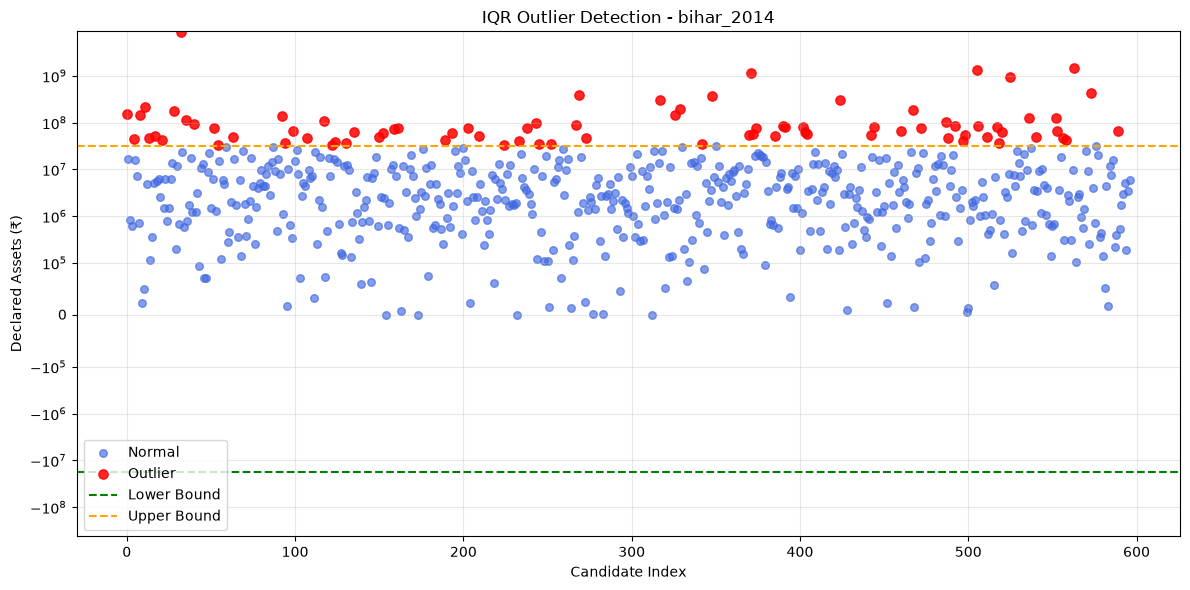


FILE: bihar_2014.csv
Total candidates: 597
Outliers detected: 82
Lower bound: -18,049,550.00
Upper bound: 32,136,930.00

Detected Outliers:
                           Candidate  Total Assets
                       Kaushal Yadav     154566136
                          Abu Qaiser      45138014
                         Ajay Nishad     145712654
               Akhilesh Prasad Singh     216275454
                        Akshay Verma      47845505
                    Alok Kumar Mehta      51615071
                     Amarnath Tiwari      43329826
                        Angesh Kumar     179440000
                   Anil Kumar Sharma    8498803720
                          Anu Shukla     115649612
                 Ashish Ranjan Sinha      94210202
                 Awanish Kumar Singh      75781467
                    Bagi Kumar Verma      32766379
                     Barun Kumar Jha      48626946
                    Chandramohan Jha     138813648
                       Chhedi Paswan      3

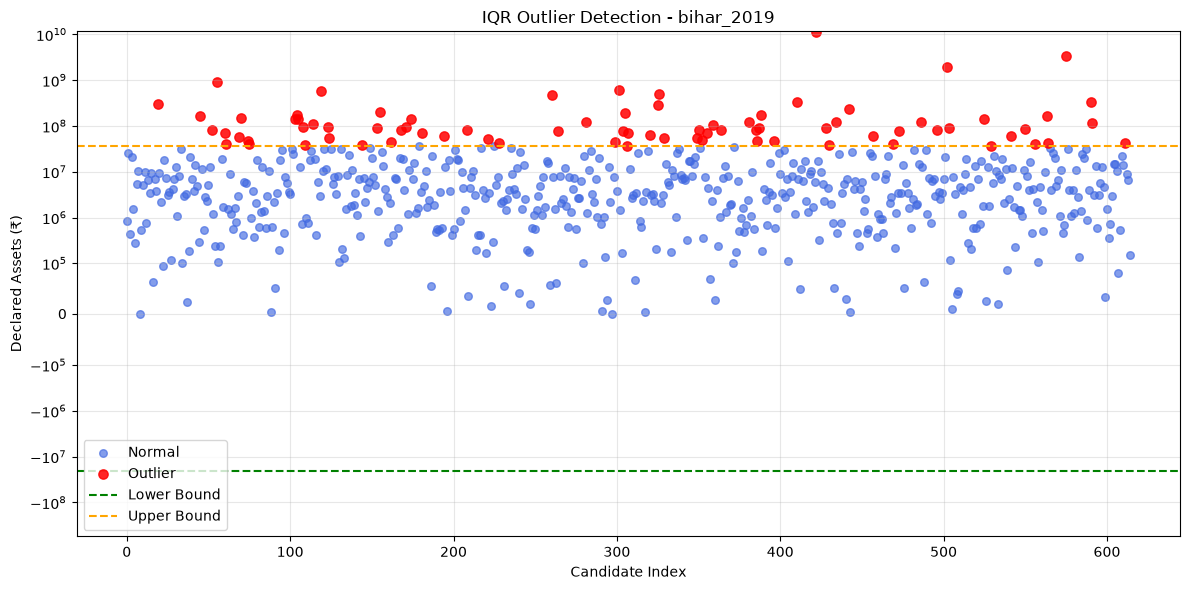


FILE: bihar_2019.csv
Total candidates: 615
Outliers detected: 80
Lower bound: -20,357,762.25
Upper bound: 36,903,603.75

Detected Outliers:
                  Candidate  Total Assets
                Ajay Nishad     298867486
                 Anil Kumar     162240912
             Anirudh Prasad      79825395
               Arbind Kumar     912002858
                 Arun Kumar      69473960
               Arvind Kumar      41043115
           Ashok Kumar Azad      56786845
          Ashok Kumar Gupta     147248402
          Ashok Kumar Yadav      46699125
      Ashwini Kumar Choubey      40183612
     Brijesh Kumar Kushwaha     144190332
              Chandan Singh     176720167
         Chandeshwar Prasad     139271693
              Chandrika Roy      96944980
              Chhedi Paswan      37786578
Choudhary Mahbub Ali Kaisar     109788313
               Deepak Yadav     569431975
            Devendra Rakesh      96715000
             Devendra Singh      53290135
       Dinesh Chand

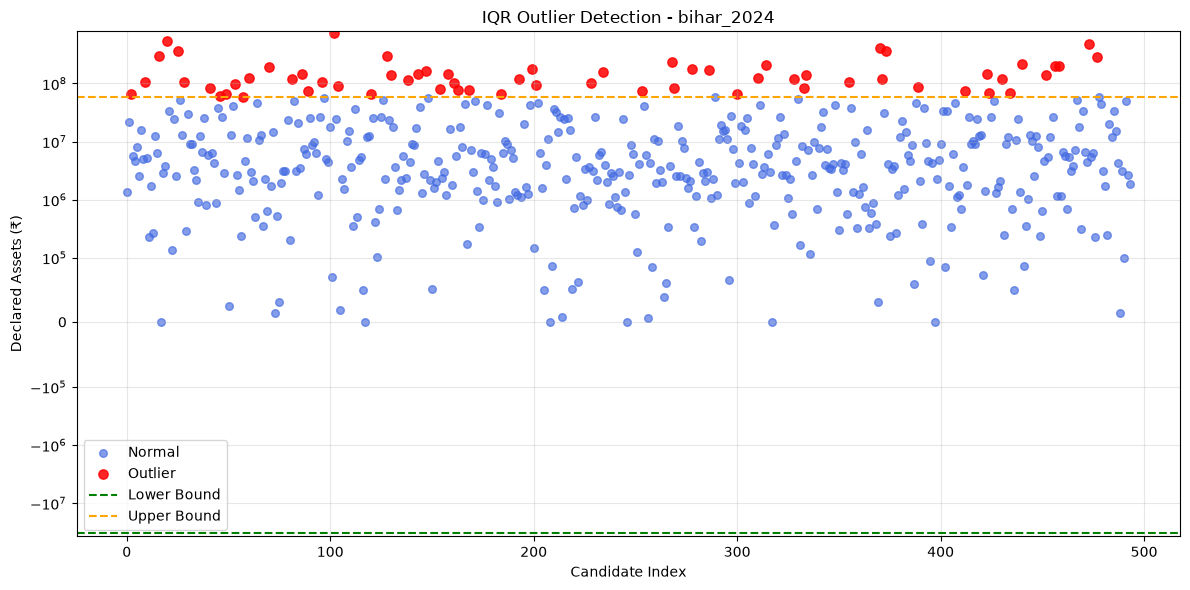


FILE: bihar_2024.csv
Total candidates: 494
Outliers detected: 63
Lower bound: -32,554,743.62
Upper bound: 57,987,239.38

Detected Outliers:
                           Candidate  Total Assets
                  Aakash Kumar Singh      65933186
                   Abhay Kumar Sinha     107718589
                         Ajay Nishad     296291687
                        Ajeet Sharma     545151545
            Akhileshwar Prasad Singh     360085130
                    Alok Kumar Mehta     105815493
                          Anil Kumar      84736820
                      Archana Kumari      61656118
                         Arun Bharti      64870319
                          Arun Kumar      99021663
                   Ashok Kumar Yadav      58583773
                Ashutosh Vinay Kumar     122452780
                   Baidya Nath Mehta     191045076
                        Bikash Kumar     117810727
                  Chandeshwar Prasad     144682826
               Chandra Kishor Thakur      7

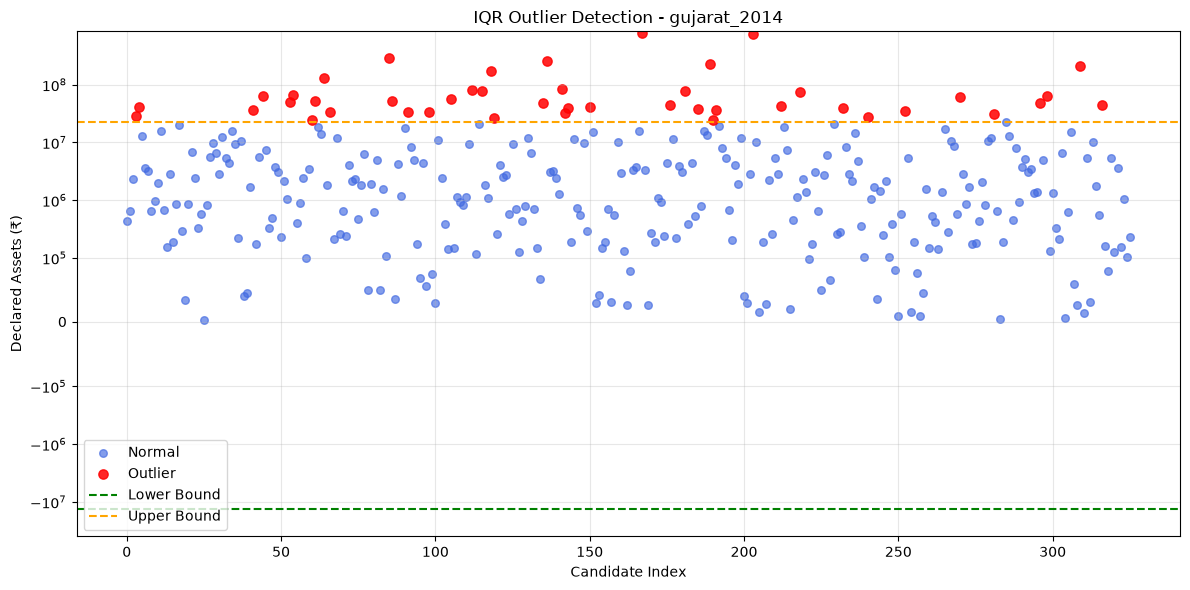


FILE: gujarat_2014.csv
Total candidates: 326
Outliers detected: 44
Lower bound: -13,364,720.75
Upper bound: 22,954,461.25

Detected Outliers:
                        Candidate  Total Assets
      Anilkumar Chhitubhai Bhagat      28598975
            Anilkumar Kasturchand      41494101
   Chavda Manubhai Parsottambhaix      36141803
     Choudhary Adambhai Nasirbhai      63893750
        Desai Khodabhai Laljibhai      50258019
    Desai Naishadhbhai Bhupatbhai      66444237
           Dinesh Babulal Vaghela      24387875
          Dinsha Jhavarbhai Patel      52207873
                        K C Patel     131141867
     Solanki Kiritbhai Premjibhai      34085266
    Jadeja Kandhalbhai Sarmanbhai     283945804
       Jagatsinh Laljibhai Vasava      51129838
     Jayeshbhai Ambalalbhai Patel      33426809
  Kachhadiya Naranbhai Bhikhabhai      34164801
               Keshavji L Saradva      56738000
     Koli Patel Somabhai Gandalal      79184058
               Lal Krishna Advani      75

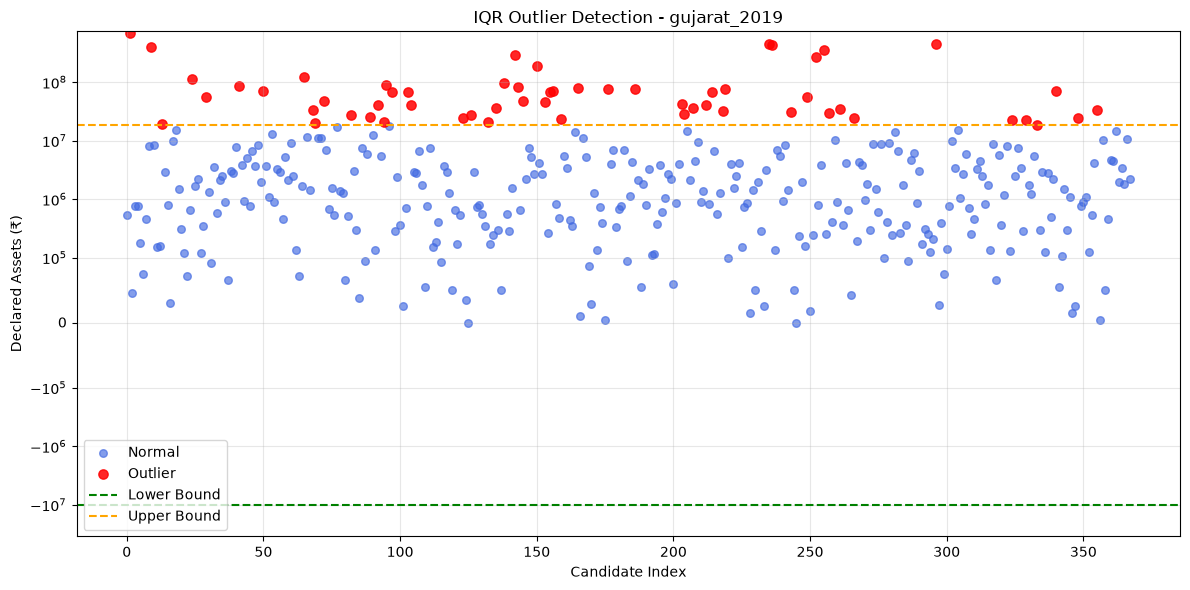


FILE: gujarat_2019.csv
Total candidates: 368
Outliers detected: 58
Lower bound: -10,276,199.38
Upper bound: 18,064,919.62

Detected Outliers:
                         Candidate  Total Assets
                         A J Patel     698773712
                         Amit Shah     403275307
            Ashok Vallabhbhai Pate      19012482
  Bhanderi Amarshibhai Chhaganbhai     112734000
     Bharatbhai Madhavsinh Solanki      54490955
                    Bimalbhai Shah      86398716
 Chaudhari Tusharbhai Amarsinhbhai      69345867
         Chavda Chatursinh Javanji     120468223
            Chavda Vinod Lakhamshi      33508455
                 Chhotubhai Vasava      20146320
      Dabhi Bharatsinhji Shankarji      47373221
Dhameliya Piyushkumar Vallabhabhai      26773999
      Dipika Jitendrakumar Sutaria      25570000
                        Chandraben      40641649
            Rahul Vasudevbhai Vyas      20924425
                 Solanki Kiritbhai      89474039
                      Dr

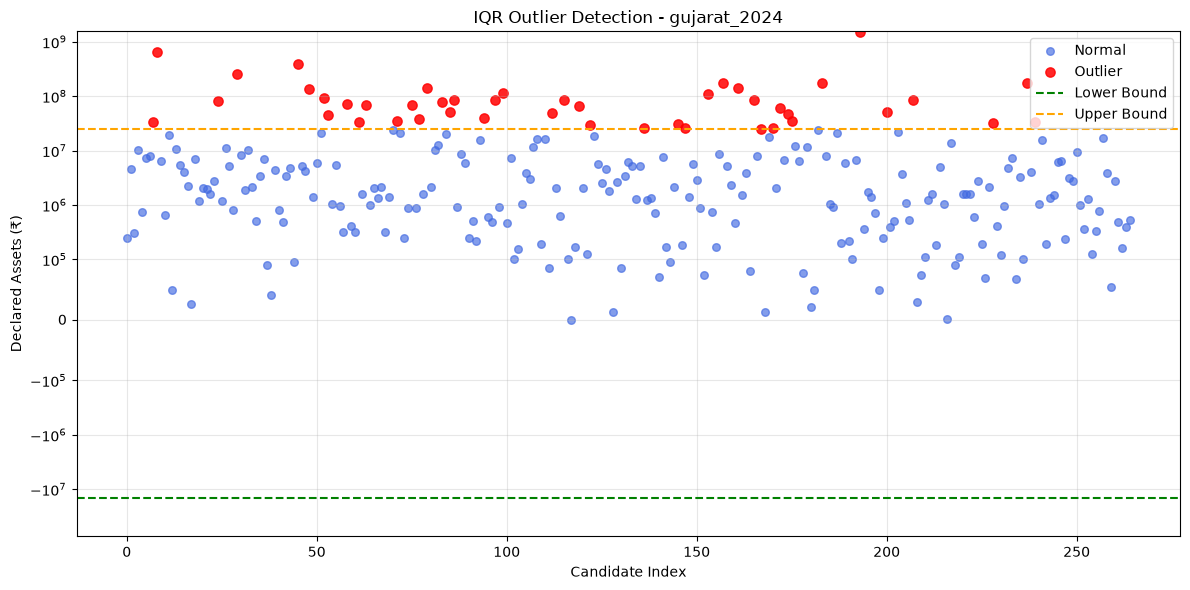


FILE: gujarat_2024.csv
Total candidates: 265
Outliers detected: 44
Lower bound: -14,373,461.00
Upper bound: 25,246,379.00

Detected Outliers:
                        Candidate  Total Assets
                      Amit Chavda      33927324
                        Amit Shah     656712498
              Balvant Chhatraliya      81375000
          Bharat Yogendra Makwana     255854377
                        C R Patil     394930044
          Chandanji Talaji Thakor     137202075
        Chaudhari Tushar Amarsinh      91990661
     Chaudhary Siddharth Amarsinh      45958292
           Chavda Vinod Lakhamshi      70980147
   Chudasama Rajeshbhai Naranbhai      33452812
     Dabhi Bharatsinhji Shankarji      68430049
                 Devusinh Chauhan      34976572
          Dhaval Laxmanbhai Patel      67850853
      Dilipbhai Chhotubhai Vasava      38025530
               Dineshbhai Makwana     141769586
                Mansukh Mandaviya      79504705
           Rahul Vasudevbhai Vyas      50

In [75]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Configuration
DATA_FOLDER = Path("clean")

FILES = [
    "andhra_2014.csv",
    "andhra_2019.csv",
    "andhra_2024.csv",
    "bihar_2014.csv",
    "bihar_2019.csv",
    "bihar_2024.csv",
    "gujarat_2014.csv",
    "gujarat_2019.csv",
    "gujarat_2024.csv"
]

ASSET_COLUMN = "Total Assets"
CANDIDATE_COLUMN = "Candidate"

IQR_MULTIPLIER = 1.5


# IQR detection function
def detect_outliers_iqr(data, multiplier=1.5):

    Q1 = np.percentile(data, 25)
    Q3 = np.percentile(data, 75)

    IQR = Q3 - Q1

    lower_bound = Q1 - multiplier * IQR
    upper_bound = Q3 + multiplier * IQR

    outlier_mask = (
        (data < lower_bound) |
        (data > upper_bound)
    )

    return outlier_mask, lower_bound, upper_bound


# Process each file
def process_file(file_path):

    df = pd.read_csv(file_path)

    # Convert assets to numeric
    asset_values = pd.to_numeric(
        df[ASSET_COLUMN].astype(str)
        .str.replace(r"[₹,]", "", regex=True)
        .str.strip(),
        errors="coerce"
    )

    valid_mask = (
        asset_values.notna() &
        np.isfinite(asset_values)
    )

    valid_df = df.loc[valid_mask].copy()
    values = asset_values.loc[valid_mask].to_numpy()

    # Detect outliers
    outlier_mask, lower, upper = detect_outliers_iqr(
        values, IQR_MULTIPLIER
    )

    valid_df["IQR_Outlier"] = outlier_mask

    # Plot
    plt.figure(figsize=(12, 6))

    normal_mask = ~outlier_mask

    plt.scatter(
        np.where(normal_mask)[0],
        values[normal_mask],
        color="royalblue",
        label="Normal",
        alpha=0.65,
        s=30
    )

    plt.scatter(
        np.where(outlier_mask)[0],
        values[outlier_mask],
        color="red",
        label="Outlier",
        alpha=0.85,
        s=45
    )

    # Show IQR boundaries
    plt.axhline(
        lower,
        color="green",
        linestyle="--",
        label="Lower Bound"
    )

    plt.axhline(
        upper,
        color="orange",
        linestyle="--",
        label="Upper Bound"
    )

    # Log-like scaling for better visibility
    plt.yscale("symlog", linthresh=1e5)

    plt.title(f"IQR Outlier Detection - {file_path.stem}")
    plt.xlabel("Candidate Index")
    plt.ylabel("Declared Assets (₹)")

    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    # Print results
    outliers = valid_df.loc[outlier_mask]

    print("\n", "=" * 60)
    print(f"FILE: {file_path.name}")
    print("=" * 60)

    print(f"Total candidates: {len(valid_df)}")
    print(f"Outliers detected: {len(outliers)}")
    print(f"Lower bound: {lower:,.2f}")
    print(f"Upper bound: {upper:,.2f}")

    if len(outliers) > 0:
        print("\nDetected Outliers:")

        print(
            outliers[
                [CANDIDATE_COLUMN, ASSET_COLUMN]
            ].to_string(index=False)
        )

    return valid_df


# Run for all nine files
all_iqr_results = {}

for filename in FILES:

    file_path = DATA_FOLDER / filename

    if not file_path.exists():
        print(f"File not found: {filename}")
        continue

    all_iqr_results[filename] = process_file(file_path)